In [1]:
from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urljoin, urlsplit, urlunsplit
from urllib.robotparser import RobotFileParser
from importlib.metadata import version

import hashlib
import json
import re
import time
import unicodedata

import pandas as pd
import requests
import trafilatura

from bs4 import BeautifulSoup
from langdetect import detect, DetectorFactory
from IPython.display import display


RANDOM_STATE = 42
DetectorFactory.seed = RANDOM_STATE

# "collect": discover and download publicly accessible pages.
# "replay": rebuild outputs using saved pages only, without internet requests.
MODE = "collect"

MIN_WORDS = 100
MAX_DISCOVERED_PER_SOURCE = 20
REQUEST_DELAY = 2
TIMEOUT = 25

USER_AGENT = "InGenAcademicCorpusCollector/1.0"

DATA_DIR = Path("data")
CACHE_DIR = DATA_DIR / "html_cache"

DATA_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

CANDIDATE_PATH = DATA_DIR / "W05_URL_Manifest.csv"
CORPUS_PATH = DATA_DIR / "W05_Text_Corpus_Raw.csv"
LOG_PATH = DATA_DIR / "W05_Collection_Log.csv"
SUMMARY_PATH = DATA_DIR / "W05_Source_Summary.csv"

session = requests.Session()
session.headers.update({"User-Agent": USER_AGENT})

robots_cache = {}
last_request = {}

print("Mode:", MODE)
print("Random seed:", RANDOM_STATE)

Mode: collect
Random seed: 42


In [2]:
SOURCES = [
    {
        "source_name": "InGen Dynamics",
        "source_category": "company_content",
        "seed_urls": [
            "https://www.ingendynamics.com/fari.html"
        ],
        "discovery_urls": [],
        "allowed_path": r"^/fari\.html$",
    },
    {
        "source_name": "ElliQ",
        "source_category": "company_content",
        "seed_urls": [],
        "discovery_urls": [
            "https://elliq.com/blogs/elliq-blog",
            "https://elliq.com/blogs/elliq-blog?page=2",
            "https://elliq.com/blogs/elliq-blog?page=3",
        ],
        "allowed_path": r"^/blogs/elliq-blog/[^/]+/?$",
    },
    {
        "source_name": "AARP",
        "source_category": "press_coverage",
        "seed_urls": [
            "https://www.aarp.org/health/conditions-treatments/"
            "ai-companion-bots-fight-loneliness-improve-health/"
        ],
        "discovery_urls": [
            "https://www.aarp.org/health/conditions-treatments/"
            "ai-companion-bots-fight-loneliness-improve-health/"
        ],
        "allowed_path": r"^/.*",
    },
    {
        "source_name": "Associated Press",
        "source_category": "press_coverage",
        "seed_urls": [
            "https://apnews.com/article/"
            "a343409477b7aea350254f94daf52eb7"
        ],
        "discovery_urls": [],
        "allowed_path": r"^/article/.*",
    },
    {
        "source_name": "New York State Office for the Aging",
        "source_category": "government_program",
        "seed_urls": [
            "https://aging.ny.gov/"
            "transforming-care-older-adults-three-years-success-"
            "ny-older-adults-living-elliq"
        ],
        "discovery_urls": [
            "https://aging.ny.gov/"
            "transforming-care-older-adults-three-years-success-"
            "ny-older-adults-living-elliq"
        ],
        "allowed_path": r"^/.*",
    },
]

# Used for link discovery, not for generating analytical labels.
DISCOVERY_PATTERN = re.compile(
    r"elliq|fari|companion.{0,30}robot|robot.{0,30}companion"
    r"|eldercare|elder-care|social.{0,15}robot",
    flags=re.I,
)

def relevant_document(text):
    """Keep branded or clearly relevant eldercare robotics documents."""
    branded = re.search(r"\b(elliq|fari)\b", text, flags=re.I)

    robotics = re.search(
        r"\b(robot|robots|robotic|robotics)\b",
        text,
        flags=re.I,
    )

    eldercare = re.search(
        r"older adults|elderly|eldercare|senior|aging|ageing",
        text,
        flags=re.I,
    )

    return bool(branded or (robotics and eldercare))

In [3]:
# Additional source candidates.
# Collection remains automatic; these are configured starting URLs.

EXTRA_SOURCES = [
    {
        "source_name": "The Guardian",
        "source_category": "press_coverage",
        "seed_urls": [
            "https://www.theguardian.com/us-news/2021/aug/13/"
            "elliq-robot-companion-seniors",

            "https://www.theguardian.com/society/2023/may/21/"
            "care-bots-care-tech-uk-robots-carers-emily-kenway",

            "https://www.theguardian.com/us-news/2021/jun/03/"
            "care-bots-on-the-rise-elder-care",
        ],
        "discovery_urls": [],
        "allowed_path": r"^/.*",
    },
    {
        "source_name": "WHYY",
        "source_category": "press_coverage",
        "seed_urls": [
            "https://whyy.org/segments/"
            "how-ai-companion-robots-are-helping-seniors-feel-less-lonely/"
        ],
        "discovery_urls": [],
        "allowed_path": r"^/segments/.*",
    },
    {
        "source_name": "IEEE Spectrum",
        "source_category": "press_coverage",
        "seed_urls": [
            "https://spectrum.ieee.org/"
            "elliq-a-social-home-robot-for-older-adults-now-available-for-preorder"
        ],
        "discovery_urls": [],
        "allowed_path": r"^/.*",
    },
    {
        "source_name": "The Senior List",
        # An editorial review, not an individual customer's review.
        "source_category": "editorial_review",
        "seed_urls": [
            "https://www.theseniorlist.com/aging-in-place/elliq/"
        ],
        "discovery_urls": [],
        "allowed_path": r"^/aging-in-place/.*",
    },
    {
        "source_name": "NYS Government Press Releases",
        "source_category": "government_program",
        "seed_urls": [
            "https://apps.cio.ny.gov/apps/mediacontact/public/view.cfm"
            "?parm=E4E6D5FF-C4A8-BF7F-60D8C2CB69442AF4",

            "https://apps.cio.ny.gov/apps/mediacontact/public/view.cfm"
            "?parm=B77F3A9A-FB62-3F99-FD0B530026BAE616",
        ],
        "discovery_urls": [],
        "allowed_path": r"^/apps/mediacontact/.*",
    },
]

# Avoid adding the same source repeatedly when rerunning this cell.
existing_names = {
    source["source_name"]
    for source in SOURCES
}

for source in EXTRA_SOURCES:
    if source["source_name"] not in existing_names:
        SOURCES.append(source)
        existing_names.add(source["source_name"])

print("Configured sources:", len(SOURCES))

Configured sources: 10


In [4]:
def sha256(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def normalize_url(url):
    parts = urlsplit(url)

    if parts.scheme not in {"http", "https"}:
        raise ValueError("Unsupported URL scheme.")

    # Remove fragments; preserve query parameters.
    return urlunsplit((
        parts.scheme.lower(),
        parts.netloc.lower(),
        parts.path or "/",
        parts.query,
        "",
    ))


def wait_for_host(url, delay=REQUEST_DELAY):
    host = urlsplit(url).netloc
    elapsed = time.monotonic() - last_request.get(host, 0)

    if elapsed < delay:
        time.sleep(delay - elapsed)

    last_request[host] = time.monotonic()


def get_robot_rules(url):
    parts = urlsplit(url)
    origin = f"{parts.scheme}://{parts.netloc}"

    if origin in robots_cache:
        return robots_cache[origin]

    robots_url = origin + "/robots.txt"
    wait_for_host(robots_url)

    response = session.get(
        robots_url,
        timeout=TIMEOUT,
        allow_redirects=True,
    )

    parser = RobotFileParser()
    parser.set_url(robots_url)

    if response.status_code in {404, 410}:
        parser.parse([])
    elif response.status_code == 200:
        parser.parse(response.text.splitlines())
    else:
        raise RuntimeError(
            f"robots.txt unavailable: HTTP {response.status_code}"
        )

    robots_cache[origin] = parser
    return parser


def fetch_page(url):
    url = normalize_url(url)
    cache_path = CACHE_DIR / f"{sha256(url)}.json"

    if cache_path.exists():
        return json.loads(cache_path.read_text(encoding="utf-8"))

    if MODE == "replay":
        raise FileNotFoundError("Page is not in the saved cache.")

    current_url = url

    for _ in range(6):
        rules = get_robot_rules(current_url)

        if not rules.can_fetch(USER_AGENT, current_url):
            raise PermissionError("URL disallowed by robots.txt.")

        delay = rules.crawl_delay(USER_AGENT)
        delay = max(REQUEST_DELAY, delay or 0)

        if delay > 60:
            raise RuntimeError("Crawl delay exceeds this collector's limit.")

        wait_for_host(current_url, delay)

        response = session.get(
            current_url,
            timeout=TIMEOUT,
            allow_redirects=False,
        )

        if response.status_code in {301, 302, 303, 307, 308}:
            location = response.headers.get("Location")

            if not location:
                raise RuntimeError("Redirect has no destination.")

            current_url = normalize_url(
                urljoin(current_url, location)
            )
            continue

        response.raise_for_status()

        content_type = response.headers.get(
            "Content-Type", ""
        ).lower()

        if "html" not in content_type:
            raise ValueError("Response is not an HTML page.")

        if response.encoding is None:
            response.encoding = response.apparent_encoding

        snapshot = {
            "requested_url": url,
            "final_url": current_url,
            "collected_at_utc": datetime.now(
                timezone.utc
            ).isoformat(),
            "html": response.text,
        }

        cache_path.write_text(
            json.dumps(snapshot, ensure_ascii=False),
            encoding="utf-8",
        )

        return snapshot

    raise RuntimeError("Too many redirects.")

In [5]:
# Refresh discovery after fixing non-HTTP link handling.
# Keep MODE = "collect" for this step.

if MODE != "collect":
    raise ValueError("Set MODE = 'collect' before refreshing discovery.")

discovery_log = []
candidate_rows = []

for source in SOURCES:
    discovered = set()

    for index_url in source["discovery_urls"]:
        try:
            snapshot = fetch_page(index_url)

            soup = BeautifulSoup(
                snapshot["html"],
                "html.parser",
            )

            index_host = urlsplit(
                snapshot["final_url"]
            ).netloc.removeprefix("www.")

            for link in soup.select("a[href]"):
                href = link.get("href", "").strip()

                if not href:
                    continue

                try:
                    raw_url = urljoin(
                        snapshot["final_url"],
                        href,
                    )

                    # Skip mailto:, tel:, javascript:, etc.
                    if urlsplit(raw_url).scheme.lower() not in {
                        "http", "https"
                    }:
                        continue

                    article_url = normalize_url(raw_url)
                    parts = urlsplit(article_url)

                except ValueError:
                    # One malformed link should not stop the page.
                    continue

                article_host = parts.netloc.removeprefix("www.")

                if article_host != index_host:
                    continue

                if not re.match(
                    source["allowed_path"],
                    parts.path,
                ):
                    continue

                discovery_text = (
                    link.get_text(" ", strip=True)
                    + " "
                    + parts.path
                )

                if DISCOVERY_PATTERN.search(discovery_text):
                    discovered.add(article_url)

            discovery_log.append({
                "stage": "discovery",
                "source_name": source["source_name"],
                "source_url": index_url,
                "status": "success",
                "message": "",
            })

        except Exception as error:
            discovery_log.append({
                "stage": "discovery",
                "source_name": source["source_name"],
                "source_url": index_url,
                "status": "failed",
                "message": str(error),
            })

    seeds = {
        normalize_url(url)
        for url in source["seed_urls"]
    }

    selected_urls = seeds | set(
        sorted(discovered)[:MAX_DISCOVERED_PER_SOURCE]
    )

    for url in sorted(selected_urls):
        candidate_rows.append({
            "source_name": source["source_name"],
            "source_category": source["source_category"],
            "source_url": url,
            "access_method": (
                "configured_seed"
                if url in seeds
                else "automatic_link_discovery"
            ),
        })

candidates = (
    pd.DataFrame(candidate_rows)
    .drop_duplicates("source_url")
    .sort_values(
        ["source_category", "source_name", "source_url"]
    )
    .reset_index(drop=True)
)

# Back up the previous manifest before saving the refreshed one.
if CANDIDATE_PATH.exists():
    backup_path = CANDIDATE_PATH.with_name(
        "W05_URL_Manifest_backup_"
        + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
        + ".csv"
    )

    CANDIDATE_PATH.rename(backup_path)

candidates.to_csv(
    CANDIDATE_PATH,
    index=False,
    encoding="utf-8-sig",
)

print("Candidate documents:", len(candidates))

display(
    candidates.groupby("source_name")
    .size()
    .to_frame("candidates")
)

display(pd.DataFrame(discovery_log))

Candidate documents: 23


,candidates
source_name,
AARP,2
Associated Press,1
ElliQ,10
IEEE Spectrum,1
InGen Dynamics,1
NYS Government Press Releases,2
New York State Office for the Aging,1
The Guardian,3
The Senior List,1


,stage,source_name,source_url,status,message
0,discovery,ElliQ,https://elliq.com/blogs/elliq-blog,success,
1,discovery,ElliQ,https://elliq.com/blogs/elliq-blog?page=2,success,
2,discovery,ElliQ,https://elliq.com/blogs/elliq-blog?page=3,success,
3,discovery,AARP,https://www.aarp.org/health/conditions-treatme...,success,
4,discovery,New York State Office for the Aging,https://aging.ny.gov/transforming-care-older-a...,failed,Response is not an HTML page.


In [6]:
CORPUS_COLUMNS = [
    "document_id",
    "source_category",
    "source_name",
    "source_url",
    "final_url",
    "title",
    "publication_date",
    "collection_date",
    "collected_at_utc",
    "access_method",
    "product",
    "language",
    "text_scope",
    "text_raw",
    "word_count",
    "text_hash",
    "html_hash",
    "data_origin",
]

records = []
collection_log = []

seen_urls = set()
seen_text_hashes = set()


for item in candidates.to_dict("records"):
    log_entry = {
        "stage": "collection",
        "source_name": item["source_name"],
        "source_url": item["source_url"],
        "status": "",
        "message": "",
    }

    try:
        snapshot = fetch_page(item["source_url"])
        final_url = normalize_url(snapshot["final_url"])

        if final_url in seen_urls:
            log_entry["status"] = "duplicate_url"
            collection_log.append(log_entry)
            continue

        extracted = trafilatura.extract(
            snapshot["html"],
            url=final_url,
            output_format="json",
            with_metadata=True,
            include_comments=False,
            include_tables=False,
            favor_precision=True,
        )

        if not extracted:
            raise ValueError("No substantive text extracted.")

        document = json.loads(extracted)
        text = (document.get("text") or "").strip()
        title = document.get("title") or ""

        word_count = len(text.split())

        if word_count < MIN_WORDS:
            log_entry["status"] = "too_short"
            log_entry["message"] = f"{word_count} words"
            collection_log.append(log_entry)
            continue

        if not relevant_document(title + "\n" + text):
            log_entry["status"] = "irrelevant"
            collection_log.append(log_entry)
            continue

        language = detect(text)

        if language != "en":
            log_entry["status"] = "non_english"
            collection_log.append(log_entry)
            continue

        normalized_text = unicodedata.normalize("NFKC", text)
        normalized_text = re.sub(
            r"\s+", " ", normalized_text
        ).strip().casefold()

        text_hash = sha256(normalized_text)

        if text_hash in seen_text_hashes:
            log_entry["status"] = "duplicate_text"
            collection_log.append(log_entry)
            continue

        products = [
            product
            for product in ["Fari", "ElliQ"]
            if re.search(
                rf"\b{re.escape(product)}\b",
                title + "\n" + text,
                flags=re.I,
            )
        ]

        records.append({
            "document_id": "DOC_" + sha256(final_url)[:16],
            "source_category": item["source_category"],
            "source_name": item["source_name"],
            "source_url": item["source_url"],
            "final_url": final_url,
            "title": title,
            "publication_date": document.get("date") or "",
            "collection_date": snapshot["collected_at_utc"][:10],
            "collected_at_utc": snapshot["collected_at_utc"],
            "access_method": item["access_method"],
            "product": "; ".join(products) or "Comparable eldercare robotics",
            "language": language,
            "text_scope": "automatically_extracted_main_text",
            "text_raw": text,
            "word_count": word_count,
            "text_hash": text_hash,
            "html_hash": sha256(snapshot["html"]),
            "data_origin": "PUBLIC_WEB",
        })

        seen_urls.add(final_url)
        seen_text_hashes.add(text_hash)

        log_entry["status"] = "accepted"

    except Exception as error:
        log_entry["status"] = "failed"
        log_entry["message"] = str(error)

    collection_log.append(log_entry)


corpus = pd.DataFrame(
    records,
    columns=CORPUS_COLUMNS,
).sort_values("document_id").reset_index(drop=True)

print("Accepted documents:", len(corpus))

Accepted documents: 21


In [7]:
corpus.to_csv(
    CORPUS_PATH,
    index=False,
    encoding="utf-8-sig",
)

logs = pd.DataFrame(discovery_log + collection_log)

logs.to_csv(
    LOG_PATH,
    index=False,
    encoding="utf-8-sig",
)

summary = (
    corpus.groupby(
        ["source_category", "source_name"],
        as_index=False,
    )
    .agg(
        document_count=("document_id", "size"),
        total_words=("word_count", "sum"),
        first_collection_date=("collection_date", "min"),
        last_collection_date=("collection_date", "max"),
    )
)

summary.to_csv(
    SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig",
)

environment = {
    "random_seed": RANDOM_STATE,
    "mode": MODE,
    "min_words": MIN_WORDS,
    "packages": {
        package: version(package)
        for package in [
            "requests",
            "beautifulsoup4",
            "trafilatura",
            "langdetect",
            "pandas",
        ]
    },
}

(DATA_DIR / "W05_Collection_Config.json").write_text(
    json.dumps(environment, indent=2),
    encoding="utf-8",
)

print("Collection outputs saved.")
print("Documents:", len(corpus))
print("Distinct publishers:", corpus["source_name"].nunique())
print("Source categories:", corpus["source_category"].nunique())

display(summary)

if not logs.empty:
    display(
        logs.groupby(["stage", "status"])
        .size()
        .to_frame("count")
    )

if corpus["source_name"].nunique() < 3:
    print(
        "Collection incomplete: fewer than three publishers "
        "have accepted documents."
    )

if not corpus.empty:
    # Reproducible sample for manual quality review.
    preview = corpus.sample(
        n=min(5, len(corpus)),
        random_state=RANDOM_STATE,
    ).copy()

    preview["text_preview"] = preview["text_raw"].str[:500]

    display(preview[
        [
            "source_name",
            "title",
            "word_count",
            "text_preview",
        ]
    ])
else:
    print("No documents accepted. Inspect the collection log.")

Collection outputs saved.
Documents: 21
Distinct publishers: 8
Source categories: 4


,source_category,source_name,document_count,total_words,first_collection_date,last_collection_date
0,company_content,ElliQ,10,9480,2026-10-06,2026-10-06
1,company_content,InGen Dynamics,1,1739,2026-10-06,2026-10-06
2,editorial_review,The Senior List,1,1258,2026-10-06,2026-10-06
3,government_program,NYS Government Press Releases,2,1849,2026-10-06,2026-10-06
4,press_coverage,AARP,2,2134,2026-10-06,2026-10-06
5,press_coverage,IEEE Spectrum,1,617,2026-10-06,2026-10-06
6,press_coverage,The Guardian,3,4958,2026-10-06,2026-10-06
7,press_coverage,WHYY,1,419,2026-10-06,2026-10-06


count
stage      status         
collection accepted     21
           failed        2
discovery  failed        1
           success       4

,source_name,title,word_count,text_preview
0,ElliQ,The Emotional Toll of Caregiving and How to Pr...,904,Caring for an aging parent or loved one can be...
17,The Senior List,ElliQ Review: a Robot Companion for Seniors │ ...,1258,ElliQ Review: Can a Robot Be a Companion for S...
15,ElliQ,How Technology Is Changing Caregiving at Home,909,How Technology Is Changing Caregiving at Home\...
1,ElliQ,"How to Choose Between Home Care, Assisted Livi...",993,"When you are caring for aging parents, few dec..."
8,ElliQ,What Yale Researchers Discovered About How You...,1000,Most people think of aging as something that s...


In [8]:
# Prepare collected text without overwriting the raw corpus.

prepared = pd.read_csv(
    CORPUS_PATH,
    keep_default_na=False,
)

def remove_confirmed_page_noise(row):
    text = row["text_raw"]

    if row["source_name"] == "AARP":
        kept_lines = []

        for line in text.splitlines():
            stripped = line.strip()

            if stripped == "AARP Hearing Center":
                continue

            if re.fullmatch(
                r"-?\s*Related Benefit\s+\d+",
                stripped,
                flags=re.I,
            ):
                continue

            kept_lines.append(line)

        text = "\n".join(kept_lines)

    # Preserve capitalization, punctuation, and paragraph structure.
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()


prepared["text_for_nlp"] = prepared.apply(
    remove_confirmed_page_noise,
    axis=1,
)

prepared["prepared_word_count"] = (
    prepared["text_for_nlp"].str.split().str.len()
)

prepared["characters_removed"] = (
    prepared["text_raw"].str.len()
    - prepared["text_for_nlp"].str.len()
)

prepared["review_flag"] = ""

# A title suggesting restricted access requires a completeness check.
possible_restricted_content = prepared["title"].str.contains(
    r"members\s+only|subscriber\s+only",
    case=False,
    regex=True,
    na=False,
)

prepared.loc[
    possible_restricted_content,
    "review_flag",
] = "Check whether extracted article is complete"

too_short = prepared["prepared_word_count"] < MIN_WORDS

prepared.loc[
    too_short,
    "review_flag",
] += "; Below minimum length after preparation"

prepared["review_flag"] = (
    prepared["review_flag"].str.strip("; ")
)

# Automated checks do not replace human quality review.
prepared["manual_review_status"] = "pending"

PREPARED_PATH = DATA_DIR / "W05_Text_Corpus_Prepared.csv"

prepared.to_csv(
    PREPARED_PATH,
    index=False,
    encoding="utf-8-sig",
)

print("Prepared documents:", len(prepared))
print(
    "Documents with review flags:",
    prepared["review_flag"].ne("").sum(),
)

display(
    prepared.groupby(
        ["source_category", "source_name"]
    )
    .size()
    .to_frame("document_count")
)

display(
    prepared.loc[
        prepared["source_name"].eq("AARP"),
        [
            "title",
            "characters_removed",
            "prepared_word_count",
            "review_flag",
        ],
    ]
)

Prepared documents: 21
Documents with review flags: 1


document_count
source_category    source_name                                  
company_content    ElliQ                                      10
                   InGen Dynamics                              1
editorial_review   The Senior List                             1
government_program NYS Government Press Releases               2
press_coverage     AARP                                        2
                   IEEE Spectrum                               1
                   The Guardian                                3
                   WHYY                                        1

,title,characters_removed,prepared_word_count,review_flag
16,How Older Adults Are Using Companion Robots to...,120,722,Check whether extracted article is complete
19,"The Benefits of Robotic Pets for Dementia, Lon...",120,1366,


In [9]:
# Preserve all prepared documents, but hold flagged items out of analysis.

prepared["analysis_eligible"] = prepared["review_flag"].eq("")

analysis_corpus = prepared.loc[
    prepared["analysis_eligible"]
].copy()

excluded_documents = prepared.loc[
    ~prepared["analysis_eligible"]
].copy()

# Save eligibility decisions alongside the prepared text.
prepared.to_csv(
    PREPARED_PATH,
    index=False,
    encoding="utf-8-sig",
)

analysis_corpus.to_csv(
    DATA_DIR / "W05_Text_Corpus_Analysis.csv",
    index=False,
    encoding="utf-8-sig",
)

excluded_documents.to_csv(
    DATA_DIR / "W05_Text_Corpus_Excluded.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Prepared documents:", len(prepared))
print("Provisionally eligible:", len(analysis_corpus))
print("Held out for review:", len(excluded_documents))

display(
    excluded_documents[
        ["title", "final_url", "review_flag"]
    ]
)

Prepared documents: 21
Provisionally eligible: 20
Held out for review: 1


,title,final_url,review_flag
16,How Older Adults Are Using Companion Robots to...,https://www.aarp.org/health/conditions-treatme...,Check whether extracted article is complete


In [10]:
# Apply corpus review corrections using cached HTML

from pathlib import Path
import hashlib
import json
import re

import pandas as pd
import trafilatura
from bs4 import BeautifulSoup

DATA_DIR = Path("data")
CACHE_DIR = DATA_DIR / "html_cache"

INPUT_PATH = DATA_DIR / "W05_Text_Corpus_Analysis.csv"
REVIEWED_PATH = DATA_DIR / "W05_Text_Corpus_Reviewed.csv"
HOLDOUT_PATH = DATA_DIR / "W05_Text_Corpus_Review_Holdout.csv"
AUDIT_PATH = DATA_DIR / "W05_Corpus_Review_Log.csv"

corpus = pd.read_csv(INPUT_PATH, keep_default_na=False)

# Load the existing HTML snapshots. No live requests are made.
cached_pages = {}

for path in sorted(CACHE_DIR.glob("*.json")):
    try:
        snapshot = json.loads(path.read_text(encoding="utf-8"))

        if isinstance(snapshot, dict) and isinstance(snapshot.get("html"), str):
            for key in ("requested_url", "final_url"):
                url = snapshot.get(key)
                if url:
                    cached_pages.setdefault(url, snapshot)
    except (OSError, UnicodeError, json.JSONDecodeError):
        continue


def find_snapshot(row):
    for column in ("final_url", "source_url"):
        snapshot = cached_pages.get(row[column])
        if snapshot is not None:
            return snapshot
    return None


# These markers were observed in the Fari extraction.
encoding_markers = re.compile(r"Ã|â|Î»|\ufffd")


def recover_html_encoding(html):
    """Attempt reversible recovery of UTF-8 decoded as Latin-1/Windows-1252."""
    candidates = [(html, "original cached HTML")]

    for encoding in ("latin-1", "cp1252"):
        try:
            corrected = html.encode(encoding).decode("utf-8")
            candidates.append((corrected, f"{encoding} → UTF-8"))
        except (UnicodeEncodeError, UnicodeDecodeError):
            pass

    return min(
        candidates,
        key=lambda item: len(encoding_markers.findall(item[0]))
    )


def clean_page_noise(text, source):
    actions = []
    kept = []
    seen_government_paragraphs = set()

    for line in text.splitlines():
        line = line.strip()

        if not line:
            continue

        # Remove the government release's organizational boilerplate.
        if (
            source == "NYS Government Press Releases"
            and line == "About the New York State Office for the Aging"
        ):
            actions.append("Removed trailing organizational boilerplate")
            break

        # Remove AARP's membership sales section.
        if source == "AARP" and line == "AARP Membership":
            actions.append("Removed membership promotion")
            break

        remove = False

        if source == "AARP":
            remove = (
                line == "AARP Hearing Center"
                or bool(re.fullmatch(
                    r"-?\s*(?:Experience|Related Benefit)\s+\d+", line
                ))
            )

        elif source == "WHYY":
            remove = (
                line.startswith("This story is from The Pulse,")
                or line == "Find our full episode on loneliness here."
                or line == "Listen to the full story above."
            )

        elif source == "The Guardian":
            remove = line.startswith((
                "- Emily Kenway is the author",
                "- Alexandra Mateescu is a researcher",
                "- Automating Care is our new series",
            ))

        if remove:
            actions.append("Removed identified promotional/metadata line")
            continue

        # Remove identical long paragraphs within government releases.
        if source == "NYS Government Press Releases":
            key = re.sub(r"\s+", " ", line).casefold()

            if len(key) >= 100:
                if key in seen_government_paragraphs:
                    actions.append("Removed repeated paragraph")
                    continue
                seen_government_paragraphs.add(key)

        kept.append(line)

    return "\n".join(kept), actions


audit = []
reviewed_rows = []

for _, row in corpus.iterrows():
    result = row.to_dict()
    source = row["source_name"]
    text = row["text_for_nlp"]
    actions = []
    issues = []

    result["title_before_review"] = row["title"]
    result["publication_date_extracted"] = row["publication_date"]
    result["title_origin"] = "automatically_extracted"
    result["reviewed_cache_hash"] = ""

    # Repair Fari from its cached HTML, not from already damaged text.
    if source == "InGen Dynamics":
        snapshot = find_snapshot(row)

        if snapshot is None:
            issues.append("Fari HTML cache unavailable")
        else:
            html, encoding_action = recover_html_encoding(snapshot["html"])

            extracted = trafilatura.extract(
                html,
                url=row["final_url"],
                output_format="json",
                with_metadata=True,
                include_comments=False,
                include_tables=False,
                favor_precision=True,
            )

            document = json.loads(extracted) if extracted else {}
            repaired_text = document.get("text") or ""
            repaired_title = document.get("title") or ""

            if (
                len(repaired_text.split()) >= 100
                and "fari" in repaired_text.casefold()
                and not encoding_markers.search(
                    repaired_text + " " + repaired_title
                )
            ):
                text = repaired_text
                result["title"] = repaired_title or row["title"]
                actions.append(f"Re-extracted Fari: {encoding_action}")
                result["reviewed_cache_hash"] = hashlib.sha256(
                    html.encode("utf-8")
                ).hexdigest()
            else:
                issues.append("Fari encoding repair needs further inspection")

        # The extracted date has not been verified as a publication date.
        result["publication_date"] = ""
        actions.append("Marked Fari publication date as unknown")

    # Recover the missing conclusion from the cached Senior List page.
    if source == "The Senior List" and not re.search(
        r"(?im)^\s*Bottom Line\s*$", text
    ):
        snapshot = find_snapshot(row)
        conclusion = []

        if snapshot is not None:
            soup = BeautifulSoup(snapshot["html"], "html.parser")

            heading = soup.find(
                lambda tag:
                    tag.name in ("h2", "h3")
                    and tag.get_text(" ", strip=True).casefold() == "bottom line"
            )

            if heading is not None:
                for element in heading.find_all_next(
                    ["p", "h2", "h3", "h4", "h5", "h6"]
                ):
                    if element.name != "p":
                        break

                    paragraph = element.get_text(" ", strip=True)

                    if paragraph:
                        conclusion.append(paragraph)

        if conclusion:
            text += "\nBottom Line\n" + "\n".join(conclusion)
            actions.append("Recovered missing concluding section")
            result["reviewed_cache_hash"] = hashlib.sha256(
                snapshot["html"].encode("utf-8")
            ).hexdigest()
        else:
            issues.append("Senior List concluding section not recovered")

    # Use descriptive titles, explicitly labeled as analyst-assigned.
    if source == "NYS Government Press Releases":
        year = row["publication_date"][:4]
        descriptive_titles = {
            "2022": "NYSOFA introduces ElliQ to older adults in New York",
            "2023": "NYSOFA reports ElliQ pilot outcomes and partnership continuation",
        }

        if year in descriptive_titles:
            result["title"] = descriptive_titles[year]
            result["title_origin"] = "analyst_assigned_descriptive_title"
            actions.append("Assigned descriptive government release title")

    text, cleaning_actions = clean_page_noise(text, source)
    actions.extend(cleaning_actions)

    result["text_for_nlp"] = text
    result["prepared_word_count"] = len(text.split())
    result["reviewed_text_hash"] = hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()
    result["review_status"] = "uploaded_text_reviewed"
    result["review_flag"] = "; ".join(issues)
    result["analysis_eligible"] = (
        not issues and result["prepared_word_count"] >= 100
    )

    reviewed_rows.append(result)
    audit.append({
        "document_id": row["document_id"],
        "source_name": source,
        "actions": "; ".join(actions) or "No correction required",
        "remaining_issues": "; ".join(issues),
    })

reviewed = pd.DataFrame(reviewed_rows)
eligible = reviewed.loc[reviewed["analysis_eligible"]].copy()
holdout = reviewed.loc[~reviewed["analysis_eligible"]].copy()

eligible.to_csv(REVIEWED_PATH, index=False, encoding="utf-8-sig")
holdout.to_csv(HOLDOUT_PATH, index=False, encoding="utf-8-sig")
pd.DataFrame(audit).to_csv(AUDIT_PATH, index=False, encoding="utf-8-sig")

print(f"Documents checked: {len(reviewed)}")
print(f"Ready for NLP: {len(eligible)}")
print(f"Unresolved documents: {len(holdout)}")
print(f"Reviewed corpus: {REVIEWED_PATH}")

if not holdout.empty:
    display(holdout[["source_name", "title", "review_flag"]])

display(pd.DataFrame(audit))

Documents checked: 20
Ready for NLP: 20
Unresolved documents: 0
Reviewed corpus: data\W05_Text_Corpus_Reviewed.csv


,document_id,source_name,actions,remaining_issues
0,DOC_02273cdab72e6af6,ElliQ,No correction required,
1,DOC_0df1fe3eec3c36f4,ElliQ,No correction required,
2,DOC_0f057b60b2e06fdb,ElliQ,No correction required,
3,DOC_18973ef41134ed44,InGen Dynamics,Re-extracted Fari: latin-1 → UTF-8; Marked Far...,
4,DOC_50ffbca5694c8ab5,ElliQ,No correction required,
5,DOC_5da508bf5e967d1d,ElliQ,No correction required,
6,DOC_601dcb0a9e7cfc80,The Guardian,Removed identified promotional/metadata line,
7,DOC_76ed7a86d9237deb,ElliQ,No correction required,
8,DOC_775ed64b8f6204c2,ElliQ,No correction required,
9,DOC_780610e1f4509b20,The Guardian,Removed identified promotional/metadata line; ...,


In [11]:
# Cell 11 — Validate the saved corpus

corpus = pd.read_csv(REVIEWED_PATH, keep_default_na=False)

normalized_text = (
    corpus["text_for_nlp"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.casefold()
)

assert corpus["document_id"].is_unique, "Duplicate document IDs"
assert corpus["final_url"].is_unique, "Duplicate final URLs"
assert normalized_text.is_unique, "Duplicate document texts"
assert normalized_text.ne("").all(), "Empty document text"
assert corpus["text_for_nlp"].str.split().str.len().ge(100).all(), \
    "A document contains fewer than 100 words"
assert corpus["review_flag"].eq("").all(), "Unresolved review flags"

fari = corpus.loc[
    corpus["source_name"].eq("InGen Dynamics")
].iloc[0]

senior_review = corpus.loc[
    corpus["source_name"].eq("The Senior List")
].iloc[0]

assert not encoding_markers.search(
    fari["title"] + " " + fari["text_for_nlp"]
), "Fari still contains encoding markers"

assert re.search(
    r"(?im)^\s*Bottom Line\s*$",
    senior_review["text_for_nlp"]
), "Senior List conclusion is missing"

print("Final corpus checks passed.")
print(f"Documents: {len(corpus)}")
print(f"Publishers: {corpus['source_name'].nunique()}")
print(f"Source categories: {corpus['source_category'].nunique()}")

print("\nFari — repaired text preview:")
print(fari["text_for_nlp"][:600])

print("\nSenior List — recovered conclusion:")
print(
    senior_review["text_for_nlp"]
    .rsplit("\nBottom Line\n", 1)[-1]
)

Final corpus checks passed.
Documents: 20
Publishers: 8
Source categories: 4

Fari — repaired text preview:
Fari is designed to deliver clinical-grade health monitoring with the warmth of a trusted friend — combining advanced AI with an unwavering commitment to dignity, privacy, and human authority.
Fari is being designed to address the three dimensions of eldercare that matter most — clinical health monitoring, emotional wellbeing, and physical safety.
Designed for continuous, non-invasive vital sign tracking — heart rate, SpO₂, respiratory rate, skin temperature, and blood pressure estimation. AI models are being developed to detect subtle health pattern changes before they become emergencies.
Our

Senior List — recovered conclusion:
In the words of Intuition Robotics, ElliQ is a “voice-operated care companion designed to empower independence and support you in taking control of your social, mental, and physical well-being.” In all of these capacities, I think it falls short.
ElliQ c

In [12]:
# Cell 12 — Install the Day 2 dependency
# Run once during environment setup.

#%pip install nltk

In [13]:
#Imports, reproducibility settings, and NLTK resources

from pathlib import Path
import random
import hashlib
import json

import numpy as np
import pandas as pd
import nltk

from nltk import word_tokenize, pos_tag
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from IPython.display import display


RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

DATA_DIR = Path("data")
INPUT_PATH = DATA_DIR / "W05_Text_Corpus_Reviewed.csv"

NLTK_DATA_DIR = DATA_DIR / "nltk_data"
NLTK_DATA_DIR.mkdir(parents=True, exist_ok=True)

nltk.data.path.insert(0, str(NLTK_DATA_DIR.resolve()))


resources = {
    "stopwords": [
        "corpora/stopwords",
        "corpora/stopwords.zip",
    ],
    "wordnet": [
        "corpora/wordnet",
        "corpora/wordnet.zip",
    ],
    "averaged_perceptron_tagger_eng": [
        "taggers/averaged_perceptron_tagger_eng",
        "taggers/averaged_perceptron_tagger_eng.zip",
    ],
}

for resource, locations in resources.items():
    available = False

    for location in locations:
        try:
            nltk.data.find(location)
            available = True
            break
        except LookupError:
            continue

    if not available:
        nltk.download(
            resource,
            download_dir=str(NLTK_DATA_DIR.resolve()),
            quiet=True,
            raise_on_error=True,
        )


# Test that the resources can actually be loaded.
english_stopwords = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

assert lemmatizer.lemmatize("robots", pos="n") == "robot"
assert pos_tag(["Robots", "help", "caregivers"], lang="eng")

# preserve_line=True skips sentence segmentation.
# We need word tokens for document-level analysis.
example_tokens = word_tokenize(
    "Robots help older adults.",
    preserve_line=True,
)

print("NLTK resources are ready.")
print("NLTK version:", nltk.__version__)
print("Random seed:", RANDOM_STATE)
print("English stopwords:", len(english_stopwords))
print("Example tokens:", example_tokens)

NLTK resources are ready.
NLTK version: 3.10.3
Random seed: 42
English stopwords: 198
Example tokens: ['Robots', 'help', 'older', 'adults', '.']


In [14]:
#Load the reviewed corpus

if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find: {INPUT_PATH.resolve()}\n"
        "Place W05_Text_Corpus_Reviewed.csv in the data folder."
    )

corpus = pd.read_csv(
    INPUT_PATH,
    encoding="utf-8-sig",
    keep_default_na=False,
)

required_columns = {
    "document_id",
    "source_name",
    "source_category",
    "title",
    "text_for_nlp",
}

missing_columns = required_columns - set(corpus.columns)

assert not missing_columns, (
    f"Missing required columns: {sorted(missing_columns)}"
)
assert not corpus.empty, "The corpus is empty."
assert corpus["document_id"].is_unique, "Duplicate document IDs."
assert corpus["text_for_nlp"].str.strip().ne("").all(), \
    "Empty document text."

if "review_flag" in corpus.columns:
    assert corpus["review_flag"].eq("").all(), \
        "The input contains unresolved review flags."

# Stable document order for subsequent processing.
corpus = corpus.sort_values("document_id").reset_index(drop=True)

INPUT_SHA256 = hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest()

print("Reviewed corpus loaded successfully.")
print("Documents:", len(corpus))
print("Publishers:", corpus["source_name"].nunique())
print("Source categories:", corpus["source_category"].nunique())

display(
    corpus.groupby("source_category")
    .size()
    .rename("document_count")
    .to_frame()
)

Reviewed corpus loaded successfully.
Documents: 20
Publishers: 8
Source categories: 4


,document_count
source_category,
company_content,11
editorial_review,1
government_program,2
press_coverage,6


In [15]:
# Configure preprocessing rules

import re
import unicodedata
from collections import Counter

MIN_TOKEN_LENGTH = 3

# Preserve these negation words in the topic-modeling text.
PRESERVED_NEGATIONS = {"not", "never", "nor"}

# Brand identifiers and residual website-related noise.
CUSTOM_STOPWORDS = {
    "elliq",
    "fari",
    "ingen",
    "aarp",
    "whyy",
    "www",
    "http",
    "https",
    "com",
    "copyright",
    "newsletter",
    "homepage",
}

STOPWORDS = (
    english_stopwords - PRESERVED_NEGATIONS
) | CUSTOM_STOPWORDS

# Expand the important two-character acronym before length filtering.
SHORT_FORM_EXPANSIONS = {
    "ai": "artificial intelligence",
}

# Check that substantive domain terms remain available.
IMPORTANT_DOMAIN_TERMS = {
    "care",
    "caregiver",
    "robot",
    "safety",
    "privacy",
    "trust",
    "loneliness",
    "engagement",
    "cost",
    "subscription",
}

assert not IMPORTANT_DOMAIN_TERMS.intersection(STOPWORDS)

print("Minimum token length:", MIN_TOKEN_LENGTH)
print("Custom stopwords:", sorted(CUSTOM_STOPWORDS))
print("Preserved negations:", sorted(PRESERVED_NEGATIONS))

Minimum token length: 3
Custom stopwords: ['aarp', 'com', 'copyright', 'elliq', 'fari', 'homepage', 'http', 'https', 'ingen', 'newsletter', 'whyy', 'www']
Preserved negations: ['never', 'nor', 'not']


In [16]:
# Normalize, tokenize, and lemmatize each document

def normalize_for_tokenization(text):
    text = unicodedata.normalize("NFKC", text)

    # Standardize curly apostrophes.
    text = text.replace("’", "'").replace("‘", "'")

    # Remove URLs and email addresses from the modeling view.
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text,
        flags=re.IGNORECASE,
    )

    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b",
        " ",
        text,
    )

    # Split hyphenated terms, e.g. "AI-powered".
    text = re.sub(r"[-‐‑‒–—]", " ", text)

    # Expand negative contractions before punctuation filtering.
    text = re.sub(
        r"\bcan't\b", "can not", text, flags=re.IGNORECASE
    )
    text = re.sub(
        r"\bwon't\b", "will not", text, flags=re.IGNORECASE
    )
    text = re.sub(
        r"\bcannot\b", "can not", text, flags=re.IGNORECASE
    )
    text = re.sub(
        r"n't\b", " not", text, flags=re.IGNORECASE
    )

    for short_form, expansion in SHORT_FORM_EXPANSIONS.items():
        text = re.sub(
            rf"\b{re.escape(short_form)}\b",
            expansion,
            text,
            flags=re.IGNORECASE,
        )

    return re.sub(r"\s+", " ", text).strip()


def wordnet_pos(treebank_tag):
    """Map NLTK POS tags to WordNet POS categories."""
    return {
        "J": wordnet.ADJ,
        "V": wordnet.VERB,
        "N": wordnet.NOUN,
        "R": wordnet.ADV,
    }.get(treebank_tag[0], wordnet.NOUN)


def preprocess_document(text):
    normalized = normalize_for_tokenization(text)

    word_tokens = word_tokenize(
        normalized,
        preserve_line=True,
    )

    # Tag before removing words so grammatical context is retained.
    tagged_tokens = pos_tag(word_tokens, lang="eng")

    cleaned_tokens = []

    for token, tag in tagged_tokens:
        token = token.lower()

        # Remove punctuation, numeric/mixed tokens, and stopwords.
        if not token.isalpha() or token in STOPWORDS:
            continue

        lemma = lemmatizer.lemmatize(
            token,
            pos=wordnet_pos(tag),
        )

        # Apply the length rule after lemmatization.
        if (
            lemma.isalpha()
            and len(lemma) >= MIN_TOKEN_LENGTH
            and lemma not in STOPWORDS
        ):
            cleaned_tokens.append(lemma)

    return {
        "tokens": cleaned_tokens,
        "text_preprocessed": " ".join(cleaned_tokens),
        "token_count_before_filter": len(word_tokens),
        "token_count": len(cleaned_tokens),
        "unique_token_count": len(set(cleaned_tokens)),
    }


# Demonstration only; this sentence is not added to the corpus.
example = (
    "Robots were helping older adults, but they weren't "
    "replacing caregivers. AI-powered assistants protected privacy."
)

example_result = preprocess_document(example)

assert "robot" in example_result["tokens"]
assert "not" in example_result["tokens"]
assert "artificial" in example_result["tokens"]
assert "intelligence" in example_result["tokens"]
assert "privacy" in example_result["tokens"]

print("Original:")
print(example)

print("\nProcessed tokens:")
print(example_result["tokens"])

print("\nPreprocessing example checks passed.")

Original:
Robots were helping older adults, but they weren't replacing caregivers. AI-powered assistants protected privacy.

Processed tokens:
['robot', 'help', 'old', 'adult', 'not', 'replace', 'artificial', 'intelligence', 'power', 'assistant', 'protect', 'privacy']

Preprocessing example checks passed.


In [17]:
# Process and validate the full corpus

features = pd.DataFrame(
    corpus["text_for_nlp"]
    .map(preprocess_document)
    .tolist(),
    index=corpus.index,
)

processed_corpus = corpus.copy()

for column in features.columns:
    processed_corpus[column] = features[column]

processed_corpus["token_retention_pct"] = (
    processed_corpus["token_count"]
    / processed_corpus["token_count_before_filter"]
    * 100
)

# Confirm the original reviewed text is preserved.
pd.testing.assert_series_equal(
    processed_corpus["text_for_nlp"],
    corpus["text_for_nlp"],
)

assert processed_corpus["token_count"].gt(0).all(), \
    "At least one document became empty."

all_tokens = [
    token
    for tokens in processed_corpus["tokens"]
    for token in tokens
]

assert all(
    token.isalpha()
    and token == token.lower()
    and len(token) >= MIN_TOKEN_LENGTH
    and token not in STOPWORDS
    for token in all_tokens
), "A processed token violates the preprocessing rules."

print("Preprocessing checks passed.")
print("Documents processed:", len(processed_corpus))
print("Total retained tokens:", len(all_tokens))
print("Vocabulary size:", len(set(all_tokens)))

display(
    processed_corpus[
        [
            "source_name",
            "title",
            "token_count_before_filter",
            "token_count",
            "token_retention_pct",
        ]
    ].round({"token_retention_pct": 1})
)

# Inspect three documents using the established random seed.
sample = processed_corpus.sample(
    n=min(3, len(processed_corpus)),
    random_state=RANDOM_STATE,
)

for _, row in sample.iterrows():
    print("\nSOURCE:", row["source_name"])
    print("TITLE:", row["title"])
    print("FIRST 40 TOKENS:", row["tokens"][:40])

# Frequency inspection for remaining noise; this is not TF-IDF.
display(
    pd.DataFrame(
        Counter(all_tokens).most_common(20),
        columns=["term", "frequency"],
    )
)

Preprocessing checks passed.
Documents processed: 20
Total retained tokens: 11683
Vocabulary size: 2441


,source_name,title,token_count_before_filter,token_count,token_retention_pct
0,ElliQ,The Emotional Toll of Caregiving and How to Pr...,985,518,52.6
1,ElliQ,"How to Choose Between Home Care, Assisted Livi...",1075,598,55.6
2,ElliQ,Your Parent Won’t Ask for Help. Here’s How to ...,905,396,43.8
3,InGen Dynamics,Fari,2025,1206,59.6
4,ElliQ,How to Help an Aging Parent Stay Socially Conn...,1036,583,56.3
5,ElliQ,The Future of Aging: Why Connection Matters Mo...,1237,620,50.1
6,The Guardian,‘Care bots’: a dream for carers or a dangerous...,2092,919,43.9
7,ElliQ,10 Activities You Can Do with ElliQ This Month,999,526,52.7
8,ElliQ,What Yale Researchers Discovered About How You...,1099,504,45.9
9,The Guardian,‘Care bots’ are on the rise and replacing huma...,983,511,52.0



SOURCE: ElliQ
TITLE: The Emotional Toll of Caregiving and How to Prevent Burnout
FIRST 40 TOKENS: ['care', 'aging', 'parent', 'love', 'one', 'one', 'meaningful', 'role', 'person', 'take', 'bring', 'moment', 'connection', 'gratitude', 'time', 'caregiving', 'also', 'bring', 'emotional', 'exhaustion', 'stress', 'sense', 'stretch', 'many', 'caregiver', 'find', 'balance', 'full', 'time', 'job', 'family', 'responsibility', 'financial', 'pressure', 'also', 'try', 'give', 'consistent', 'attention', 'senior']

SOURCE: NYS Government Press Releases
TITLE: NYSOFA introduces ElliQ to older adults in New York
FIRST 40 TOKENS: ['building', 'comprehensive', 'effort', 'battle', 'social', 'isolation', 'support', 'age', 'place', 'nysofa', 'deliver', 'voice', 'operate', 'smart', 'technology', 'home', 'old', 'program', 'nysofa', 'work', 'local', 'office', 'aging', 'partner', 'identify', 'old', 'adult', 'would', 'benefit', 'technology', 'intuition', 'robotics', 'first', 'ever', 'proactive', 'empathetic', 

,term,frequency
0,not,157
1,care,155
2,support,111
3,senior,108
4,artificial,100
5,intelligence,97
6,caregiver,93
7,help,87
8,design,80
9,family,78


In [18]:
# Export, verify, and document preprocessing

import sys

PREPROCESSED_PATH = DATA_DIR / "W05_Text_Corpus_Preprocessed.csv"
SUMMARY_PATH = DATA_DIR / "W05_Preprocessing_Summary.csv"
CONFIG_PATH = DATA_DIR / "W05_Preprocessing_Config.json"

# Confirm that the reviewed input has not changed during processing.
assert hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest() == INPUT_SHA256, \
    "The input CSV changed. Reload it and rerun preprocessing."

# Reprocess the same documents to check deterministic output.
repeated_results = (
    processed_corpus["text_for_nlp"]
    .map(preprocess_document)
    .tolist()
)

assert all(
    result["tokens"] == original_tokens
    for result, original_tokens in zip(
        repeated_results,
        processed_corpus["tokens"],
    )
), "Repeated preprocessing produced different tokens."


# Serialize token lists as JSON, so they can be recovered reliably.
export_data = processed_corpus.copy()

export_data["tokens"] = export_data["tokens"].map(
    lambda tokens: json.dumps(tokens, ensure_ascii=False)
)

export_data.to_csv(
    PREPROCESSED_PATH,
    index=False,
    encoding="utf-8-sig",
)

summary_columns = [
    "document_id",
    "source_name",
    "source_category",
    "title",
    "token_count_before_filter",
    "token_count",
    "unique_token_count",
    "token_retention_pct",
]

processed_corpus[summary_columns].to_csv(
    SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig",
)


# Record hashes of the NLTK resources actually found by the loader.
resource_hashes = {}

for resource, locations in resources.items():
    pointer = None

    for location in locations:
        try:
            pointer = nltk.data.find(location)
            break
        except LookupError:
            continue

    if pointer is None:
        raise LookupError(f"Cannot locate resource: {resource}")

    if hasattr(pointer, "zipfile"):
        resource_path = Path(pointer.zipfile.filename)
    else:
        resource_path = Path(str(pointer))

    if resource_path.is_file():
        files = [resource_path]
    elif resource_path.is_dir():
        files = sorted(
            p for p in resource_path.rglob("*") if p.is_file()
        )
    else:
        raise FileNotFoundError(
            f"Cannot inspect resource: {resource_path}"
        )

    resource_hashes[resource] = {
        (
            p.name
            if resource_path.is_file()
            else p.relative_to(resource_path).as_posix()
        ): hashlib.sha256(p.read_bytes()).hexdigest()
        for p in files
    }


config = {
    "preprocessing_version": "1.0",
    "input_file": INPUT_PATH.as_posix(),
    "input_sha256": INPUT_SHA256,
    "output_file": PREPROCESSED_PATH.as_posix(),
    "output_sha256": hashlib.sha256(
        PREPROCESSED_PATH.read_bytes()
    ).hexdigest(),
    "random_state": RANDOM_STATE,
    "python_version": sys.version.split()[0],
    "package_versions": {
        "nltk": nltk.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
    "tokenizer": "NLTK word_tokenize",
    "preserve_line": True,
    "pos_tagger": "NLTK English averaged perceptron tagger",
    "lemmatizer": "WordNetLemmatizer with POS mapping",
    "minimum_token_length": MIN_TOKEN_LENGTH,
    "alphabetic_tokens_only": True,
    "custom_stopwords": sorted(CUSTOM_STOPWORDS),
    "preserved_negations": sorted(PRESERVED_NEGATIONS),
    "effective_stopwords": sorted(STOPWORDS),
    "short_form_expansions": SHORT_FORM_EXPANSIONS,
    "nltk_resource_hashes": resource_hashes,
    "document_count": len(processed_corpus),
    "total_retained_tokens": len(all_tokens),
    "vocabulary_size": len(set(all_tokens)),
}

CONFIG_PATH.write_text(
    json.dumps(config, ensure_ascii=False, indent=2, sort_keys=True),
    encoding="utf-8",
)


# Reload the saved CSV and check that serialization preserved the data.
saved_data = pd.read_csv(
    PREPROCESSED_PATH,
    encoding="utf-8-sig",
    keep_default_na=False,
)

saved_tokens = saved_data["tokens"].map(json.loads)

assert saved_data["document_id"].tolist() == \
    processed_corpus["document_id"].tolist()

assert saved_tokens.tolist() == processed_corpus["tokens"].tolist()

assert saved_data["text_preprocessed"].tolist() == \
    processed_corpus["text_preprocessed"].tolist()

assert saved_data["text_for_nlp"].tolist() == \
    processed_corpus["text_for_nlp"].tolist()

assert saved_tokens.map(len).tolist() == \
    saved_data["token_count"].tolist()

print("Repeated preprocessing produced identical tokens.")
print("Export and reload checks passed.")
print("Documents saved:", len(saved_data))

for path in [PREPROCESSED_PATH, SUMMARY_PATH, CONFIG_PATH]:
    print("Saved:", path)

Repeated preprocessing produced identical tokens.
Export and reload checks passed.
Documents saved: 20
Saved: data\W05_Text_Corpus_Preprocessed.csv
Saved: data\W05_Preprocessing_Summary.csv
Saved: data\W05_Preprocessing_Config.json


## Day 2 — Text Preprocessing Decisions

The reviewed corpus contains 20 documents from eight publishers across
four source categories. Preprocessing creates a separate modeling view
while preserving the reviewed article text and source metadata.

| Decision | Rationale and alternative |
|---|---|
| NLTK tokenization | `word_tokenize` provides a documented tokenizer for the English article corpus. `preserve_line=True` skips sentence segmentation because this stage requires document-level word features. Whitespace splitting would provide less explicit punctuation handling; spaCy is another valid option. |
| Text normalization | Unicode normalization and standardized apostrophes reduce formatting differences. Hyphenated expressions are split into component words; preserving compounds would retain phrase identity but create more vocabulary variants. |
| Acronym expansion | `AI` is expanded to `artificial intelligence` before tokenization so its meaning survives the three-character minimum. Other short tokens follow the standard length rule. |
| Lowercasing | Tokens are lowercased after POS tagging to merge capitalization variants while allowing the tagger to see the original case. Case-sensitive features could preserve named entities but would increase vocabulary fragmentation. |
| Stopword removal | NLTK English stopwords are combined with a documented custom list of brand identifiers and website-related noise. Substantive terms such as care, safety, privacy, and cost are retained. Brand identifiers remain available in the original text and metadata. |
| Negation handling | Negative contractions are expanded, and `not`, `never`, and `nor` are retained. This preserves selected negation cues, although a bag-of-words representation does not fully capture their scope. |
| POS-aware lemmatization | WordNet lemmatization uses mapped noun, verb, adjective, and adverb tags. It produces interpretable word forms; stemming would be simpler but could produce truncated terms. POS tagging and lemmatization remain imperfect. |
| Token filtering | Only alphabetic lemmas with at least three characters are retained. This reduces punctuation and numeric noise but also excludes mixed technical identifiers and short words. |

### Validation and Reproducibility

All 20 documents remained nonempty after preprocessing. The corpus
contains 11,683 retained tokens and 2,441 unique terms.

Validation checks confirm lowercase alphabetic tokens, the minimum length,
stopword exclusion, and preservation of the reviewed text. Repeated
processing is checked for identical token lists, and the exported CSV is
reloaded to verify token serialization.

The configuration records the input and output hashes, package versions,
NLTK resource hashes, preprocessing rules, and random seed 42. Token lists
are stored as JSON strings in the CSV.

### Intended Use and Limitations

`text_preprocessed` is intended for TF-IDF and LDA. The reviewed
`text_for_nlp` field is retained for subsequent sentiment analysis because
it preserves punctuation, wording, and sentence context.

Company content accounts for 11 of the 20 documents. Term frequencies
therefore describe this collected corpus and should not be interpreted
as evidence of customer preferences or broader public opinion.
The small corpus and unequal source-category sizes limit generalization.

In [19]:
#%pip install scikit-learn matplotlib seaborn

In [20]:
from pathlib import Path
import hashlib
import json
import random

import numpy as np
import pandas as pd
import sklearn

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

DATA_DIR = Path("data")

CORPUS_PATH = DATA_DIR / "W05_Text_Corpus_Preprocessed.csv"
CONFIG_PATH = DATA_DIR / "W05_Preprocessing_Config.json"

for path in [CORPUS_PATH, CONFIG_PATH]:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing file: {path.resolve()}\n"
            "Run Day 2 Cell 18 to export the preprocessing results first."
        )

with CONFIG_PATH.open("r", encoding="utf-8") as file:
    preprocessing_config = json.load(file)

corpus_sha256 = hashlib.sha256(
    CORPUS_PATH.read_bytes()
).hexdigest()

assert corpus_sha256 == preprocessing_config["output_sha256"], (
    "The preprocessed CSV differs from the file recorded in the "
    "preprocessing configuration. Check the Day 2 exports."
)

tfidf_corpus = pd.read_csv(
    CORPUS_PATH,
    encoding="utf-8-sig",
    keep_default_na=False,
)

required_columns = {
    "document_id",
    "source_name",
    "source_category",
    "title",
    "tokens",
    "text_preprocessed",
    "token_count",
}

missing_columns = required_columns - set(tfidf_corpus.columns)

assert not missing_columns, (
    f"Missing required columns: {sorted(missing_columns)}"
)

assert not tfidf_corpus.empty
assert tfidf_corpus["document_id"].is_unique
assert tfidf_corpus["document_id"].str.strip().ne("").all()
assert tfidf_corpus["source_category"].str.strip().ne("").all()
assert tfidf_corpus["text_preprocessed"].str.strip().ne("").all()

tfidf_corpus["tokens"] = tfidf_corpus["tokens"].map(json.loads)

assert tfidf_corpus["tokens"].map(
    lambda tokens: (
        isinstance(tokens, list)
        and len(tokens) > 0
        and all(isinstance(token, str) for token in tokens)
    )
).all(), "Every document must contain a non-empty list of string tokens."

assert tfidf_corpus["tokens"].map(" ".join).equals(
    tfidf_corpus["text_preprocessed"]
), "Saved tokens do not match the preprocessed text."

saved_token_counts = pd.to_numeric(
    tfidf_corpus["token_count"],
    errors="raise",
)

assert np.array_equal(
    saved_token_counts.to_numpy(),
    tfidf_corpus["tokens"].map(len).to_numpy(),
), "Saved token counts do not match the token lists."

assert all(
    token.isalpha()
    and token == token.lower()
    and len(token) >= preprocessing_config["minimum_token_length"]
    for tokens in tfidf_corpus["tokens"]
    for token in tokens
), "Some tokens do not follow the Day 2 preprocessing rules."

observed_vocabulary = {
    token
    for tokens in tfidf_corpus["tokens"]
    for token in tokens
}

assert len(tfidf_corpus) == preprocessing_config["document_count"]
assert int(saved_token_counts.sum()) == (
    preprocessing_config["total_retained_tokens"]
)
assert len(observed_vocabulary) == (
    preprocessing_config["vocabulary_size"]
)

print("Day 3 input validation passed.")
print(f"Documents: {len(tfidf_corpus)}")
print(f"Publishers: {tfidf_corpus['source_name'].nunique()}")
print(f"Source categories: {tfidf_corpus['source_category'].nunique()}")
print(f"Retained tokens: {int(saved_token_counts.sum()):,}")
print(f"Vocabulary size: {len(observed_vocabulary):,}")
print(f"scikit-learn version: {sklearn.__version__}")

display(
    tfidf_corpus["source_category"]
    .value_counts()
    .rename_axis("source_category")
    .reset_index(name="document_count")
)

Day 3 input validation passed.
Documents: 20
Publishers: 8
Source categories: 4
Retained tokens: 11,683
Vocabulary size: 2,441
scikit-learn version: 1.9.1


,source_category,document_count
0,company_content,11
1,press_coverage,6
2,government_program,2
3,editorial_review,1


In [21]:
TFIDF_SETTINGS = {
    "analyzer": "word",
    "lowercase": False,
    "token_pattern": None,
    "stop_words": None,
    "ngram_range": (1, 1),
    "min_df": 1,
    "max_df": 1.0,
    "max_features": None,
    "use_idf": True,
    "smooth_idf": True,
    "sublinear_tf": True,
    "norm": "l2",
}

vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    **TFIDF_SETTINGS,
)

tfidf_matrix = vectorizer.fit_transform(
    tfidf_corpus["text_preprocessed"]
)

feature_names = vectorizer.get_feature_names_out()

assert tfidf_matrix.shape == (
    len(tfidf_corpus),
    len(observed_vocabulary),
)

assert set(feature_names) == observed_vocabulary
assert np.isfinite(tfidf_matrix.data).all()
assert (tfidf_matrix.getnnz(axis=1) > 0).all()

document_norms = np.sqrt(
    tfidf_matrix.multiply(tfidf_matrix).sum(axis=1)
).A1

assert np.allclose(document_norms, 1.0)

# Refit independently to verify repeatability.
repeat_vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    **TFIDF_SETTINGS,
)

repeat_matrix = repeat_vectorizer.fit_transform(
    tfidf_corpus["text_preprocessed"]
)

assert np.array_equal(
    feature_names,
    repeat_vectorizer.get_feature_names_out(),
)

difference = tfidf_matrix - repeat_matrix

assert (
    difference.nnz == 0
    or np.allclose(difference.data, 0.0, atol=1e-12, rtol=0)
)

print("TF-IDF validation passed.")
print(f"Document-term matrix shape: {tfidf_matrix.shape}")
print(f"Non-zero entries: {tfidf_matrix.nnz:,}")
print("Independent refit produced the same TF-IDF values.")

TF-IDF validation passed.
Document-term matrix shape: (20, 2441)
Non-zero entries: 6,415
Independent refit produced the same TF-IDF values.


In [22]:
mean_tfidf = np.asarray(
    tfidf_matrix.mean(axis=0)
).ravel()

document_frequency = np.asarray(
    (tfidf_matrix > 0).sum(axis=0)
).ravel()

overall_term_scores = pd.DataFrame({
    "term": feature_names,
    "mean_tfidf": mean_tfidf,
    "document_frequency": document_frequency.astype(int),
})

overall_term_scores["document_coverage_pct"] = (
    overall_term_scores["document_frequency"]
    / len(tfidf_corpus)
    * 100
)

overall_term_scores = (
    overall_term_scores
    .sort_values(
        ["mean_tfidf", "term"],
        ascending=[False, True],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

overall_top20 = overall_term_scores.head(20).copy()

overall_top20.insert(
    0,
    "rank",
    np.arange(1, len(overall_top20) + 1),
)

print("Top 20 terms by mean document-level TF-IDF:")

# Format a display copy while preserving the original numeric results.
overall_top20_display = overall_top20.copy()

overall_top20_display["mean_tfidf"] = (
    overall_top20_display["mean_tfidf"]
    .map(lambda value: f"{value:.6f}")
)

overall_top20_display["document_coverage_pct"] = (
    overall_top20_display["document_coverage_pct"]
    .map(lambda value: f"{value:.1f}%")
)

display(overall_top20_display)

Top 20 terms by mean document-level TF-IDF:


,rank,term,mean_tfidf,document_frequency,document_coverage_pct
0,1,not,0.050167,19,95.0%
1,2,support,0.048033,18,90.0%
2,3,care,0.047721,17,85.0%
3,4,senior,0.046632,13,65.0%
4,5,help,0.044521,18,90.0%
5,6,adult,0.044343,17,85.0%
6,7,artificial,0.042394,14,70.0%
7,8,intelligence,0.041473,14,70.0%
8,9,family,0.040963,17,85.0%
9,10,old,0.040574,18,90.0%


In [23]:
category_names = sorted(
    tfidf_corpus["source_category"].unique().tolist()
)

category_score_tables = []
category_centroid_vectors = []

for category in category_names:
    category_mask = (
        tfidf_corpus["source_category"].eq(category).to_numpy()
    )

    category_matrix = tfidf_matrix[category_mask]
    category_document_count = int(category_mask.sum())

    # Average document vectors to form the category centroid.
    category_mean_tfidf = np.asarray(
        category_matrix.mean(axis=0)
    ).ravel()

    category_centroid_vectors.append(category_mean_tfidf)

    category_document_frequency = np.asarray(
        (category_matrix > 0).sum(axis=0)
    ).ravel().astype(int)

    category_scores = pd.DataFrame({
        "source_category": category,
        "category_document_count": category_document_count,
        "term": feature_names,
        "mean_tfidf": category_mean_tfidf,
        "document_frequency": category_document_frequency,
    })

    category_scores["document_coverage_pct"] = (
        category_scores["document_frequency"]
        / category_document_count
        * 100
    )

    # Only rank terms that actually occur in this category.
    category_scores = (
        category_scores
        .loc[category_scores["document_frequency"] > 0]
        .sort_values(
            ["mean_tfidf", "term"],
            ascending=[False, True],
            kind="mergesort",
        )
        .reset_index(drop=True)
    )

    category_scores.insert(
        2,
        "rank",
        np.arange(1, len(category_scores) + 1),
    )

    category_score_tables.append(category_scores)

category_all_term_scores = pd.concat(
    category_score_tables,
    ignore_index=True,
)

category_top10 = (
    category_all_term_scores
    .loc[category_all_term_scores["rank"] <= 10]
    .copy()
    .reset_index(drop=True)
)

category_centroids = pd.DataFrame(
    np.vstack(category_centroid_vectors),
    index=pd.Index(category_names, name="source_category"),
    columns=feature_names,
)

assert np.isfinite(category_centroids.to_numpy()).all()
assert (np.linalg.norm(category_centroids.to_numpy(), axis=1) > 0).all()

for category in category_names:
    category_display = (
        category_top10
        .loc[
            category_top10["source_category"].eq(category),
            [
                "rank",
                "term",
                "mean_tfidf",
                "document_frequency",
                "document_coverage_pct",
            ],
        ]
        .copy()
        .reset_index(drop=True)
    )

    category_display["mean_tfidf"] = (
        category_display["mean_tfidf"]
        .map(lambda value: f"{value:.6f}")
    )

    category_display["document_coverage_pct"] = (
        category_display["document_coverage_pct"]
        .map(lambda value: f"{value:.1f}%")
    )

    number_of_documents = int(
        tfidf_corpus["source_category"].eq(category).sum()
    )

    print(f"\n{category} — {number_of_documents} document(s)")
    display(category_display)

print("\nCategory keyword analysis completed.")


company_content — 11 document(s)


,rank,term,mean_tfidf,document_frequency,document_coverage_pct
0,1,parent,0.068658,9,81.8%
1,2,support,0.063305,11,100.0%
2,3,senior,0.061626,7,63.6%
3,4,daily,0.059563,10,90.9%
4,5,care,0.059389,10,90.9%
5,6,emotional,0.057046,10,90.9%
6,7,help,0.056914,10,90.9%
7,8,not,0.054650,11,100.0%
8,9,feel,0.053669,11,100.0%
9,10,caregiver,0.053163,9,81.8%



editorial_review — 1 document(s)


,rank,term,mean_tfidf,document_frequency,document_coverage_pct
0,1,emergency,0.126186,1,100.0%
1,2,either,0.117945,1,100.0%
2,3,tell,0.115053,1,100.0%
3,4,cute,0.107911,1,100.0%
4,5,review,0.107911,1,100.0%
5,6,ryan,0.107911,1,100.0%
6,7,back,0.107859,1,100.0%
7,8,however,0.106427,1,100.0%
8,9,contact,0.104305,1,100.0%
9,10,information,0.097326,1,100.0%



government_program — 2 document(s)


,rank,term,mean_tfidf,document_frequency,document_coverage_pct
0,1,nysofa,0.175519,2,100.0%
1,2,york,0.129777,2,100.0%
2,3,intuition,0.104027,2,100.0%
3,4,partner,0.103761,2,100.0%
4,5,office,0.102138,2,100.0%
5,6,pilot,0.101474,2,100.0%
6,7,new,0.097340,2,100.0%
7,8,robotics,0.097230,2,100.0%
8,9,combat,0.090278,2,100.0%
9,10,association,0.087127,2,100.0%



press_coverage — 6 document(s)


,rank,term,mean_tfidf,document_frequency,document_coverage_pct
0,1,robot,0.053455,5,83.3%
1,2,say,0.051888,5,83.3%
2,3,not,0.050806,6,100.0%
3,4,niemiec,0.047535,1,16.7%
4,5,talk,0.046756,4,66.7%
5,6,people,0.043054,4,66.7%
6,7,year,0.042505,6,100.0%
7,8,little,0.041926,5,83.3%
8,9,like,0.041758,6,100.0%
9,10,could,0.041378,5,83.3%



Category keyword analysis completed.


In [24]:
category_similarity_values = cosine_similarity(
    category_centroids.to_numpy()
)

assert np.isfinite(category_similarity_values).all()

assert np.allclose(
    category_similarity_values,
    category_similarity_values.T,
), "The similarity matrix must be symmetric."

assert np.allclose(
    np.diag(category_similarity_values),
    1.0,
), "Each category must have similarity 1 with itself."

assert (
    category_similarity_values.min() >= -1e-12
    and category_similarity_values.max() <= 1.0 + 1e-12
), "Unexpected cosine similarity values."

category_similarity = pd.DataFrame(
    category_similarity_values,
    index=pd.Index(category_names, name="source_category"),
    columns=category_names,
)

print("Cosine similarity between category TF-IDF centroids:")
display(category_similarity.round(4))

# List each unique category pair once, excluding self-comparisons.
similarity_pairs = []

for i, category_a in enumerate(category_names):
    for j in range(i + 1, len(category_names)):
        category_b = category_names[j]

        similarity_pairs.append({
            "category_a": category_a,
            "category_b": category_b,
            "cosine_similarity": float(
                category_similarity_values[i, j]
            ),
        })

category_similarity_pairs = (
    pd.DataFrame(similarity_pairs)
    .sort_values(
        ["cosine_similarity", "category_a", "category_b"],
        ascending=[False, True, True],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

print("\nCategory pairs ranked by cosine similarity:")

display(
    category_similarity_pairs.round({
        "cosine_similarity": 4,
    })
)

print("\nCategory similarity validation passed.")

Cosine similarity between category TF-IDF centroids:


,company_content,editorial_review,government_program,press_coverage
source_category,,,,
company_content,1.0000,0.3102,0.3329,0.4613
editorial_review,0.3102,1.0000,0.1955,0.3286
government_program,0.3329,0.1955,1.0000,0.2916
press_coverage,0.4613,0.3286,0.2916,1.0000



Category pairs ranked by cosine similarity:


,category_a,category_b,cosine_similarity
0,company_content,press_coverage,0.4613
1,company_content,government_program,0.3329
2,editorial_review,press_coverage,0.3286
3,company_content,editorial_review,0.3102
4,government_program,press_coverage,0.2916
5,editorial_review,government_program,0.1955



Category similarity validation passed.


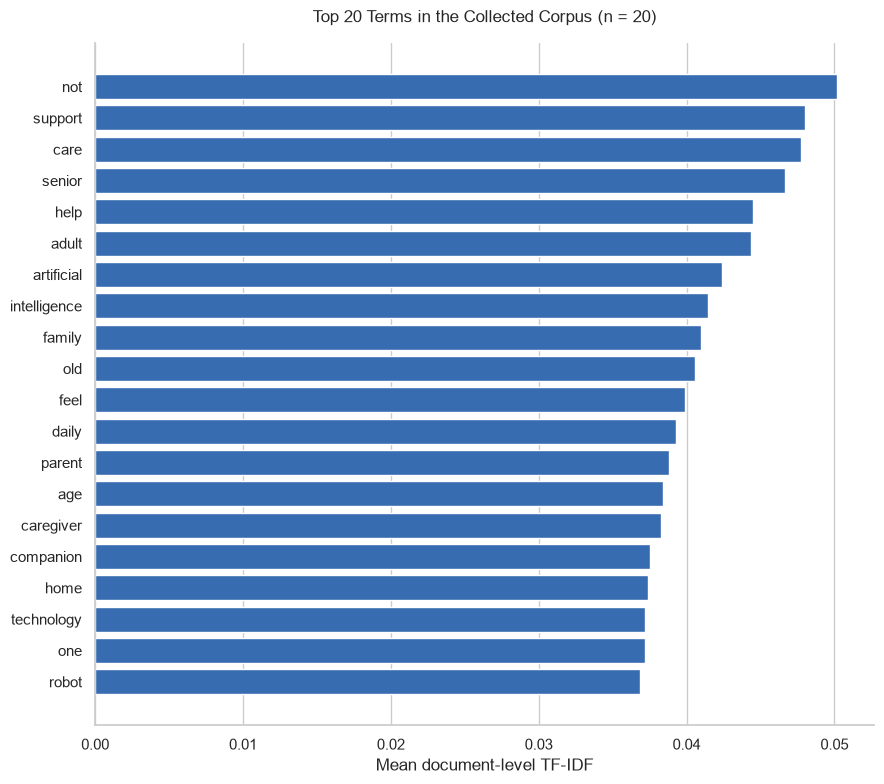

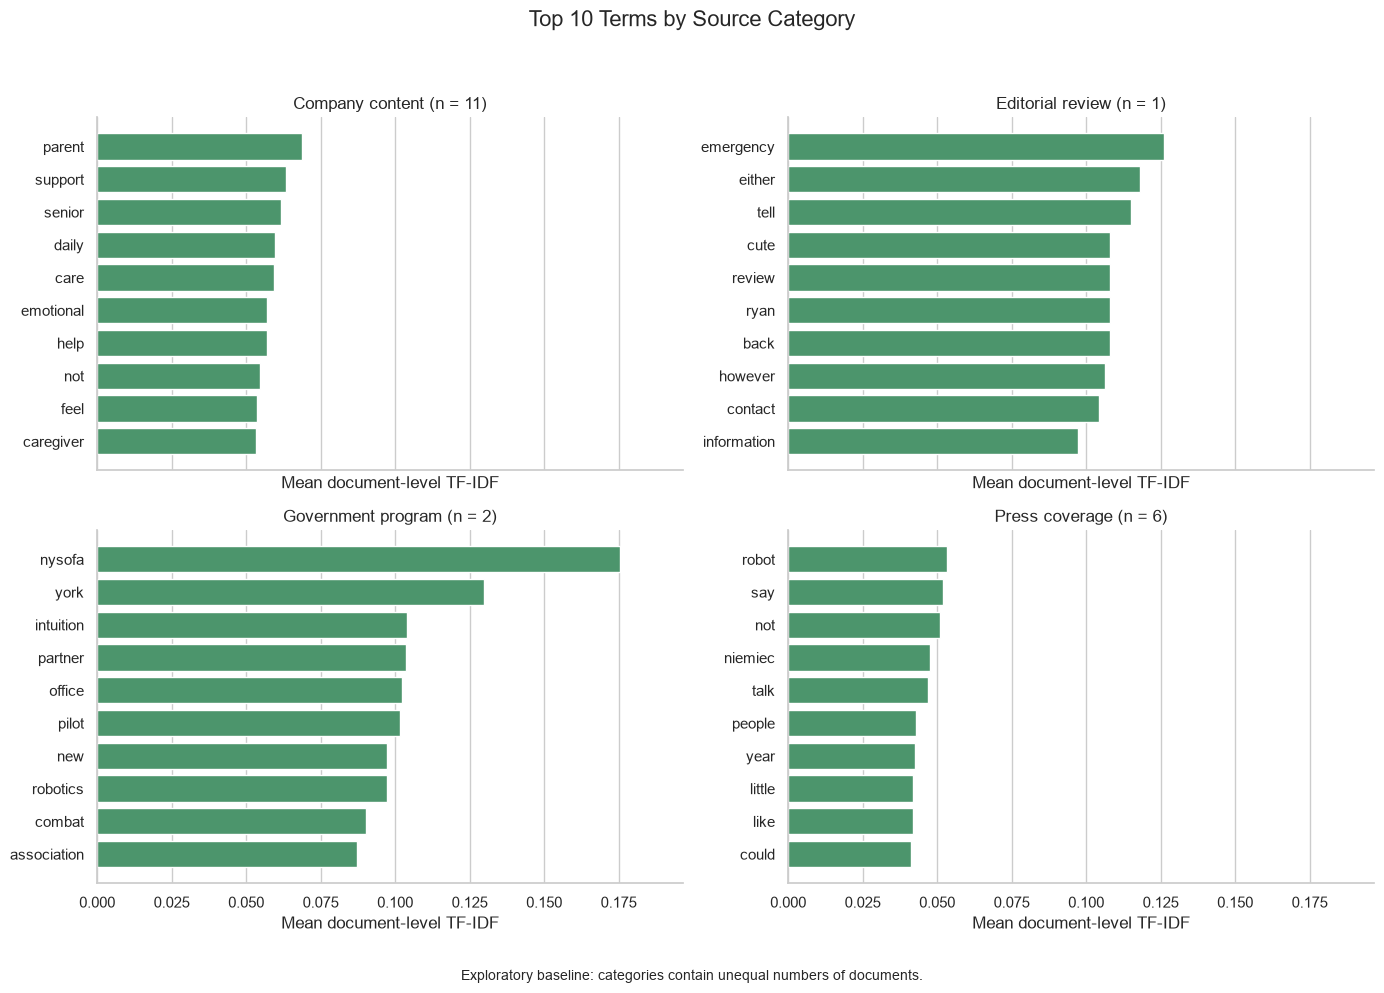

Keyword charts saved.


In [25]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Store this analysis separately so it can serve as a baseline.
# Use a new folder name when analyzing an expanded corpus.
BASELINE_DIR = DATA_DIR / "tfidf_baseline_v1"
FIGURE_DIR = BASELINE_DIR / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Apply a consistent visual style to all charts.
sns.set_theme(style="whitegrid", context="notebook")

# Convert the original category codes into readable chart labels.
category_labels = {
    "company_content": "Company content",
    "editorial_review": "Editorial review",
    "government_program": "Government program",
    "press_coverage": "Press coverage",
}


# Plot the overall Top 20 terms

# These scores are averages of document-level TF-IDF weights.
# They are not raw word counts, percentages, or sentiment scores.
fig, ax = plt.subplots(figsize=(9, 8))

ax.barh(
    overall_top20["term"],
    overall_top20["mean_tfidf"],
    color="#386CB0",
)

# Display the highest-ranked term at the top of the chart.
ax.invert_yaxis()

ax.set_xlabel("Mean document-level TF-IDF")
ax.set_ylabel("")
ax.set_title(
    f"Top 20 Terms in the Collected Corpus "
    f"(n = {len(tfidf_corpus)})",
    pad=15,
)

# Keep vertical reference lines while removing horizontal grid lines.
ax.grid(axis="y", visible=False)
sns.despine(ax=ax)

fig.tight_layout()

# Save the figure before showing it in the notebook.
fig.savefig(
    FIGURE_DIR / "W05_TFIDF_Overall_Top20.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


# Plot the Top 10 terms within each source category

# Arrange the category charts in two columns.
# Calculate the number of rows automatically from the category count.
number_of_columns = 2
number_of_rows = (
    len(category_names) + number_of_columns - 1
) // number_of_columns

fig, axes = plt.subplots(
    number_of_rows,
    number_of_columns,
    figsize=(14, 5 * number_of_rows),
    sharex=True,
    squeeze=False,
)

# Use the same horizontal scale for every category.
# This prevents independently scaled charts from exaggerating differences.
common_x_limit = category_top10["mean_tfidf"].max() * 1.12

for ax, category in zip(axes.flat, category_names):

    # Select this category's Top 10 terms and preserve their ranking.
    category_terms = (
        category_top10
        .loc[category_top10["source_category"].eq(category)]
        .sort_values("rank")
    )

    # Include the number of documents in the chart title.
    # Small categories require more cautious interpretation.
    document_count = int(
        tfidf_corpus["source_category"].eq(category).sum()
    )

    ax.barh(
        category_terms["term"],
        category_terms["mean_tfidf"],
        color="#4C956C",
    )

    ax.invert_yaxis()
    ax.set_xlim(0, common_x_limit)
    ax.set_xlabel("Mean document-level TF-IDF")
    ax.set_ylabel("")

    ax.set_title(
        f"{category_labels.get(category, category)} "
        f"(n = {document_count})"
    )

    ax.grid(axis="y", visible=False)
    sns.despine(ax=ax)

# Hide unused panels if the number of categories is odd.
for ax in list(axes.flat)[len(category_names):]:
    ax.set_visible(False)

fig.suptitle(
    "Top 10 Terms by Source Category",
    fontsize=16,
)

# Reserve space at the bottom for the sample-size limitation.
fig.tight_layout(rect=(0, 0.04, 1, 0.95))

fig.text(
    0.5,
    0.01,
    "Exploratory baseline: categories contain unequal numbers of documents.",
    ha="center",
    fontsize=10,
)

# Retain all ranked terms, including names and general words.
# Their relevance should be assessed during interpretation.
fig.savefig(
    FIGURE_DIR / "W05_TFIDF_Category_Top10.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Keyword charts saved.")

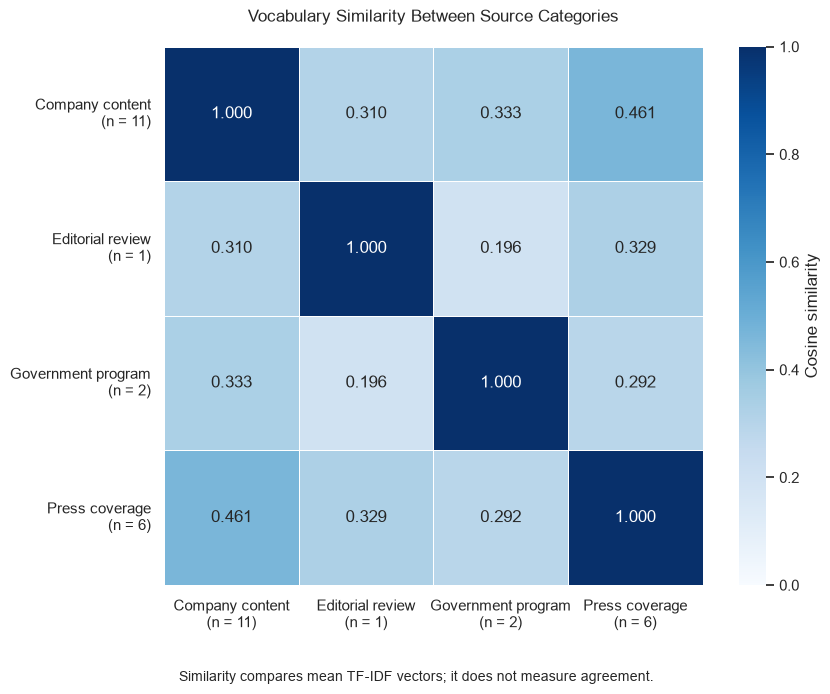

Similarity heatmap saved.


In [26]:
# Prepare readable labels with category sample sizes

heatmap_labels = []

for category in category_names:
    document_count = int(
        tfidf_corpus["source_category"].eq(category).sum()
    )

    heatmap_labels.append(
        f"{category_labels.get(category, category)}\n"
        f"(n = {document_count})"
    )


# Plot cosine similarity between category centroids

# Each centroid is the average TF-IDF vector of the documents
# in that category, calculated using the shared vocabulary and IDF.
#
# This matrix compares category centroids.
# It is not an average of all individual document-pair similarities.
fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    category_similarity,
    annot=True,          # Display the similarity inside each cell.
    fmt=".3f",           # Round displayed values to three decimals.
    cmap="Blues",
    vmin=0,              # Fix the color scale at its theoretical minimum.
    vmax=1,              # Fix the color scale at its theoretical maximum.
    square=True,
    linewidths=0.5,
    xticklabels=heatmap_labels,
    yticklabels=heatmap_labels,
    cbar_kws={"label": "Cosine similarity"},
    ax=ax,
)

# Fixing the color scale prevents small observed differences
# from appearing larger because of automatic color scaling.
ax.set_title(
    "Vocabulary Similarity Between Source Categories",
    pad=18,
)

ax.set_xlabel("")
ax.set_ylabel("")

# Keep category labels horizontal for readability.
plt.setp(ax.get_xticklabels(), rotation=0)
plt.setp(ax.get_yticklabels(), rotation=0)

fig.tight_layout(rect=(0, 0.06, 1, 1))

# Similar language does not necessarily mean similar opinions.
# The diagonal is 1 because each category is compared with itself.
fig.text(
    0.5,
    0.015,
    "Similarity compares mean TF-IDF vectors; it does not measure agreement.",
    ha="center",
    fontsize=10,
)

fig.savefig(
    FIGURE_DIR / "W05_TFIDF_Category_Similarity.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Similarity heatmap saved.")

In [27]:
import sys
import scipy

from scipy.sparse import save_npz, load_npz


# Verify that the input file has not changed

# Compare the current file hash with the hash recorded in Cell 20.
# This prevents exporting results against an unexpectedly modified input.
assert hashlib.sha256(CORPUS_PATH.read_bytes()).hexdigest() == (
    corpus_sha256
), "The input CSV changed during this analysis."


# Record the document and vocabulary order

# A sparse matrix does not store article titles or document IDs.
# This table identifies the document represented by each matrix row.
document_index = (
    tfidf_corpus[
        [
            "document_id",
            "source_name",
            "source_category",
            "title",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

document_index.insert(
    0,
    "matrix_row",
    np.arange(len(document_index)),
)

# This table identifies the term represented by each matrix column.
# Save the learned IDF weights as part of the analysis record.
vocabulary_index = pd.DataFrame({
    "matrix_column": np.arange(len(feature_names)),
    "term": feature_names,
    "idf": vectorizer.idf_,
})


# Export the numerical result tables

# Export the original numerical tables, not the formatted display copies.
# This preserves numeric values for later analysis.
tables_to_save = {
    "W05_TFIDF_Overall_AllTerms.csv": overall_term_scores,
    "W05_TFIDF_Overall_Top20.csv": overall_top20,
    "W05_TFIDF_Category_AllTerms.csv": category_all_term_scores,
    "W05_TFIDF_Category_Top10.csv": category_top10,
    "W05_TFIDF_Category_Centroids.csv":
        category_centroids.reset_index(),
    "W05_TFIDF_Category_Similarity.csv":
        category_similarity.reset_index(),
    "W05_TFIDF_Category_Similarity_Pairs.csv":
        category_similarity_pairs,
    "W05_TFIDF_Document_Index.csv": document_index,
    "W05_TFIDF_Vocabulary_Index.csv": vocabulary_index,
}

saved_paths = []

for filename, table in tables_to_save.items():
    output_path = BASELINE_DIR / filename

    table.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig",  # Supports opening Unicode text in Excel.
        float_format="%.17g",  # Retains numerical precision in the export.
    )

    saved_paths.append(output_path)


# Save and reload the sparse TF-IDF matrix

# Sparse storage avoids writing thousands of unnecessary zero values.
matrix_path = BASELINE_DIR / "W05_TFIDF_Matrix.npz"

save_npz(matrix_path, tfidf_matrix)
saved_paths.append(matrix_path)

# Confirm that saving and loading preserves the matrix values.
reloaded_matrix = load_npz(matrix_path)

assert reloaded_matrix.shape == tfidf_matrix.shape

matrix_difference = reloaded_matrix - tfidf_matrix

assert (
    matrix_difference.nnz == 0
    or np.allclose(
        matrix_difference.data,
        0.0,
        atol=1e-12,
        rtol=0,
    )
)


# Validate the saved row and column mappings

reloaded_vocabulary = pd.read_csv(
    BASELINE_DIR / "W05_TFIDF_Vocabulary_Index.csv",
    encoding="utf-8-sig",
    keep_default_na=False,
)

# Matrix columns must remain aligned with their corresponding terms.
assert reloaded_vocabulary["term"].tolist() == (
    feature_names.tolist()
)

reloaded_documents = pd.read_csv(
    BASELINE_DIR / "W05_TFIDF_Document_Index.csv",
    encoding="utf-8-sig",
    keep_default_na=False,
    dtype={"document_id": str},
)

# Matrix rows must remain aligned with their corresponding documents.
assert reloaded_documents["document_id"].tolist() == (
    document_index["document_id"].astype(str).tolist()
)


# Record settings, software versions, and output hashes

saved_paths.extend(sorted(FIGURE_DIR.glob("W05_TFIDF_*.png")))

# TF-IDF itself is deterministic and does not use random_state.
# Record the project's seed for consistency with later stochastic models.
#
# File hashes identify the specific saved artifacts.
# They do not guarantee identical PNG/NPZ file bytes across environments.
tfidf_config = {
    "analysis_version": "baseline_v1",
    "analysis_scope": "Exploratory analysis of collected public documents",
    "input_file": CORPUS_PATH.as_posix(),
    "input_sha256": corpus_sha256,
    "preprocessing_config_sha256": hashlib.sha256(
        CONFIG_PATH.read_bytes()
    ).hexdigest(),
    "random_state": RANDOM_STATE,
    "tfidf_uses_randomness": False,
    "tokenizer": "str.split",
    "vectorizer_settings": TFIDF_SETTINGS,
    "overall_ranking": "Mean TF-IDF across documents",
    "category_ranking": "Mean TF-IDF within each source category",
    "ranking_tie_breaker": "Term in alphabetical order",
    "similarity_method": "Cosine similarity between category centroids",
    "document_count": len(tfidf_corpus),
    "vocabulary_size": len(feature_names),
    "matrix_shape": list(tfidf_matrix.shape),
    "category_order": category_names,
    "category_document_counts": {
        category: int(
            tfidf_corpus["source_category"].eq(category).sum()
        )
        for category in category_names
    },
    "python_version": sys.version.split()[0],
    "package_versions": {
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__,
        "scipy": scipy.__version__,
        "matplotlib": matplotlib.__version__,
        "seaborn": sns.__version__,
    },
    "output_sha256": {
        path.relative_to(BASELINE_DIR).as_posix():
            hashlib.sha256(path.read_bytes()).hexdigest()
        for path in saved_paths
    },
}

tfidf_config_path = BASELINE_DIR / "W05_TFIDF_Config.json"

tfidf_config_path.write_text(
    json.dumps(
        tfidf_config,
        ensure_ascii=False,
        indent=2,
        sort_keys=True,
    ),
    encoding="utf-8",
)


# Print the export confirmation

print("Baseline export validation passed.")
print(f"Output folder: {BASELINE_DIR.resolve()}")
print(f"Saved tables: {len(tables_to_save)}")
print(f"Saved figures: {len(list(FIGURE_DIR.glob('W05_TFIDF_*.png')))}")
print(f"Reloaded matrix shape: {reloaded_matrix.shape}")
print("Document and vocabulary order checks passed.")
print("TF-IDF settings, package versions, and file hashes saved.")

Baseline export validation passed.
Output folder: D:\大王只想要工作\intern\Week 5\data\tfidf_baseline_v1
Saved tables: 9
Saved figures: 3
Reloaded matrix shape: (20, 2441)
Document and vocabulary order checks passed.
TF-IDF settings, package versions, and file hashes saved.


### TF-IDF Findings and Limitations

The overall keyword rankings emphasize eldercare, support, and companionship. Leading terms include “support,” “care,” “senior,” “family,” and “caregiver.” The highest-ranked term, “not,” reflects the decision to preserve negation during preprocessing. Its ranking alone does not indicate negative sentiment.

Vocabulary differs across source categories. Company content emphasizes parents, daily support, and emotional wellbeing. Government documents emphasize institutional programs through terms such as “nysofa,” “partner,” and “pilot.” Press coverage includes “robot,” “say,” and “talk,” which may reflect reporting and quoted experiences. The single editorial review includes “emergency” and “contact,” although its broader meaning requires reading the document in context. Personal names and location terms also contribute to some rankings.

Company content and press coverage have the highest observed cross-category cosine similarity (0.4613). Editorial review and government documents have the lowest (0.1955). These values describe vocabulary overlap between mean TF-IDF vectors; they do not measure agreement, sentiment, or factual consistency.

The corpus contains only 20 documents, including 11 company documents, six press articles, two government documents, and one editorial review. Findings therefore describe this collected corpus and remain exploratory. They should not be generalized to customer preferences or broader public opinion.

## LDA Topic Modeling

In [28]:
# Prepare the document-term count matrix for LDA.
# Reuse the reviewed and preprocessed corpus.

import numpy as np

from sklearn.feature_extraction.text import CountVectorizer

# Keep a separate copy for the topic-modeling stage.
# Reset the index so matrix rows follow the document order.
lda_corpus = tfidf_corpus.copy().reset_index(drop=True)

assert not lda_corpus.empty, "The corpus is empty."
assert lda_corpus["document_id"].is_unique, "Duplicate document IDs."

# The text has already been tokenized, lowercased, and lemmatized.
# Split on spaces to preserve those preprocessing decisions.
#
# Keep the full vocabulary for this initial LDA baseline.
# binary=False retains actual word counts.
LDA_COUNT_SETTINGS = {
    "tokenizer": str.split,
    "token_pattern": None,
    "lowercase": False,
    "stop_words": None,
    "ngram_range": (1, 1),
    "min_df": 1,
    "max_df": 1.0,
    "binary": False,
}

lda_count_vectorizer = CountVectorizer(**LDA_COUNT_SETTINGS)

lda_count_matrix = lda_count_vectorizer.fit_transform(
    lda_corpus["text_preprocessed"]
)

lda_feature_names = (
    lda_count_vectorizer.get_feature_names_out()
)

# Check that every document retains words.
document_token_totals = np.asarray(
    lda_count_matrix.sum(axis=1)
).ravel()

assert (document_token_totals > 0).all(), (
    "At least one document has no retained words."
)

# Counts should match the token totals saved during preprocessing.
assert np.array_equal(
    document_token_totals,
    lda_corpus["token_count"].astype(int).to_numpy(),
), "The count matrix does not match the saved token counts."

print("LDA input validation passed.")
print(f"Documents: {lda_count_matrix.shape[0]}")
print(f"Vocabulary size: {lda_count_matrix.shape[1]:,}")
print(f"Matrix shape: {lda_count_matrix.shape}")
print(f"Total word occurrences: {int(lda_count_matrix.sum()):,}")

LDA input validation passed.
Documents: 20
Vocabulary size: 2,441
Matrix shape: (20, 2441)
Total word occurrences: 11,683


In [29]:
# Compare LDA models with 3–8 topics.
# Training perplexity measures fit to the existing corpus.
# Review topic keywords before confirming the final topic count.

import pandas as pd

from sklearn.decomposition import LatentDirichletAllocation
from IPython.display import display

RANDOM_STATE = 42
TOPIC_COUNTS = range(3, 9)

LDA_MODEL_SETTINGS = {
    "learning_method": "batch",  # Use the full corpus for each update.
    "max_iter": 50,             # Maximum number of training iterations.
    "random_state": RANDOM_STATE,
    "evaluate_every": -1,       # Calculate perplexity after fitting.
    "n_jobs": 1,
}

# Store fitted models for the next topic-inspection step.
lda_models = {}
evaluation_rows = []

for k in TOPIC_COUNTS:
    print(f"Training LDA with {k} topics...", flush=True)

    model = LatentDirichletAllocation(
        n_components=k,
        **LDA_MODEL_SETTINGS,
    )

    model.fit(lda_count_matrix)

    # Evaluate every model on the same count matrix.
    training_perplexity = model.perplexity(lda_count_matrix)

    lda_models[k] = model

    evaluation_rows.append({
        "number_of_topics": k,
        "training_perplexity": training_perplexity,
    })

    print(f"Completed. Perplexity: {training_perplexity:,.2f}")

# Build the comparison table in topic-count order.
lda_evaluation = pd.DataFrame(evaluation_rows)

# Display rounded values without pandas Styler.
# The original evaluation table retains its full numeric precision.
display(
    lda_evaluation.round({"training_perplexity": 2})
)

# Identify an initial candidate using the lowest training perplexity.
# If scores tie, prefer the smaller number of topics.
provisional_k = int(
    lda_evaluation
    .sort_values(
        ["training_perplexity", "number_of_topics"]
    )
    .iloc[0]["number_of_topics"]
)

print(f"\nInitial candidate: {provisional_k} topics")
print("Next: inspect topic keywords before confirming the selection.")

Training LDA with 3 topics...
Completed. Perplexity: 1,218.27
Training LDA with 4 topics...
Completed. Perplexity: 1,174.72
Training LDA with 5 topics...
Completed. Perplexity: 1,161.88
Training LDA with 6 topics...
Completed. Perplexity: 1,154.94
Training LDA with 7 topics...
Completed. Perplexity: 1,239.37
Training LDA with 8 topics...
Completed. Perplexity: 1,209.14


,number_of_topics,training_perplexity
0,3,1218.27
1,4,1174.72
2,5,1161.88
3,6,1154.94
4,7,1239.37
5,8,1209.14



Initial candidate: 6 topics
Next: inspect topic keywords before confirming the selection.


In [30]:
# Inspect the initial candidate without retraining the model.
candidate_k = provisional_k
candidate_model = lda_models[candidate_k]

# Calculate each document's topic proportions.
# A document can contain multiple topics.
candidate_document_topics = candidate_model.transform(
    lda_count_matrix
)

# For this summary, assign each document to its highest-weight topic.
candidate_dominant_topics = (
    candidate_document_topics.argmax(axis=1)
)

dominant_document_counts = np.bincount(
    candidate_dominant_topics,
    minlength=candidate_k,
)

# Verify that model columns match the vocabulary.
assert candidate_model.components_.shape[1] == (
    len(lda_feature_names)
)

topic_rows = []

for topic_index, word_weights in enumerate(
    candidate_model.components_
):
    # Rank terms by their weight within this topic.
    top_indices = np.argsort(word_weights)[::-1][:10]
    top_terms = lda_feature_names[top_indices].tolist()

    topic_rows.append({
        "topic": f"Topic {topic_index + 1}",
        "top_10_terms": ", ".join(top_terms),
        "dominant_document_count": int(
            dominant_document_counts[topic_index]
        ),
    })

candidate_topic_summary = pd.DataFrame(topic_rows)

# Show complete keyword lists without optional styling dependencies.
with pd.option_context("display.max_colwidth", None):
    display(candidate_topic_summary)

print(
    "\nTotal documents:",
    int(dominant_document_counts.sum()),
)

,topic,top_10_terms,dominant_document_count
0,Topic 1,"not, robot, erickson, social, also, tell, say, user, conversation, like",3
1,Topic 2,"niemiec, say, new, virtual, day, wife, feel, senior, anthony, not",1
2,Topic 3,"senior, support, artificial, intelligence, care, family, adult, help, caregiver, not",10
3,Topic 4,"design, seom, model, intelligence, artificial, resident, sensor, data, every, target",1
4,Topic 5,"not, age, something, help, time, feel, shape, way, parent, often",2
5,Topic 6,"care, caregiver, not, dog, robotic, like, ingrid, caregiving, technology, people",3



Total documents: 20


In [31]:
# Compare simpler models using their existing fitted results.
# Review keyword clarity and document distribution together.

topic_comparisons = {}

for k in [3, 4, 5]:
    model = lda_models[k]

    # Calculate topic proportions and each document's dominant topic.
    document_topics = model.transform(lda_count_matrix)
    dominant_topics = document_topics.argmax(axis=1)

    document_counts = np.bincount(
        dominant_topics,
        minlength=k,
    )

    rows = []

    for topic_index, word_weights in enumerate(model.components_):
        # Extract the ten highest-weight words for this topic.
        top_indices = np.argsort(word_weights)[::-1][:10]
        top_terms = lda_feature_names[top_indices].tolist()

        rows.append({
            "topic": f"Topic {topic_index + 1}",
            "top_10_terms": ", ".join(top_terms),
            "dominant_document_count": int(
                document_counts[topic_index]
            ),
        })

    summary = pd.DataFrame(rows)
    topic_comparisons[k] = summary

    perplexity = float(
        lda_evaluation.loc[
            lda_evaluation["number_of_topics"].eq(k),
            "training_perplexity",
        ].iloc[0]
    )

    print(f"\n{k} topics — training perplexity: {perplexity:,.2f}")

    with pd.option_context("display.max_colwidth", None):
        display(summary)


3 topics — training perplexity: 1,218.27


,topic,top_10_terms,dominant_document_count
0,Topic 1,"not, design, care, caregiver, robot, say, erickson, like, use, dog",5
1,Topic 2,"not, age, feature, something, find, time, feel, shape, old, think",3
2,Topic 3,"care, senior, support, artificial, intelligence, not, help, family, adult, caregiver",12



4 topics — training perplexity: 1,174.72


,topic,top_10_terms,dominant_document_count
0,Topic 1,"not, care, robot, erickson, caregiver, say, social, like, life, also",3
1,Topic 2,"not, feature, find, shape, something, time, robot, age, think, also",3
2,Topic 3,"care, support, senior, not, artificial, intelligence, help, adult, family, caregiver",12
3,Topic 4,"design, dog, seom, robotic, resident, model, pet, care, sensor, intelligence",2



5 topics — training perplexity: 1,161.88


,topic,top_10_terms,dominant_document_count
0,Topic 1,"not, care, robot, erickson, caregiver, say, social, like, life, also",3
1,Topic 2,"not, feature, find, robot, video, call, ask, tell, however, also",2
2,Topic 3,"care, senior, support, artificial, intelligence, help, not, family, adult, caregiver",12
3,Topic 4,"design, seom, model, sensor, resident, intelligence, artificial, data, every, target",1
4,Topic 5,"not, dog, age, robotic, something, show, time, may, pet, shape",2


In [32]:
# Review the strongest representative document for each topic.
# Use the existing five-topic model; no retraining is needed.

import textwrap

review_k = 5
review_model = lda_models[review_k]

review_document_topics = review_model.transform(
    lda_count_matrix
)

review_dominant_topics = review_document_topics.argmax(axis=1)

for topic_index in range(review_k):
    print(f"\n===== Topic {topic_index + 1} =====")

    # Restrict candidates to documents dominated by this topic.
    positions = np.flatnonzero(
        review_dominant_topics == topic_index
    )

    if len(positions) == 0:
        print("No document has this topic as its dominant topic.")
        continue

    # Choose the document with the highest proportion of this topic.
    best_position = positions[
        np.argmax(
            review_document_topics[positions, topic_index]
        )
    ]

    document = lda_corpus.iloc[best_position]
    topic_proportion = review_document_topics[
        best_position, topic_index
    ]

    print("Document ID:", document["document_id"])
    print("Title:", document["title"])
    print("Publisher:", document["source_name"])
    print("Source category:", document["source_category"])
    print(f"Topic proportion: {topic_proportion:.3f}")

    # Display an excerpt from the reviewed original text.
    # This preview supports inspection; it is not a generated summary.
    preview = " ".join(
        document["text_for_nlp"].split()
    )[:700]

    print("\nReviewed text preview:")
    print(textwrap.fill(preview, width=90))


===== Topic 1 =====
Document ID: DOC_9ad8afcb88c0cf86
Title: ElliQ is 93-year-old Juanita’s friend. She’s also a robot
Publisher: The Guardian
Source category: press_coverage
Topic proportion: 0.999

Reviewed text preview:
Juanita Erickson got her robot companion about two years ago. A company representative
gave a presentation about the device to residents at the independent living facility in
the San Francisco Bay Area where Erickson resides. “I thought ‘something to liven up life
a bit … well that sounds like fun’,” says the former high school literature and journalism
teacher, who prides herself on being a lifelong learner. Erickson, 93, remembers the day
her ElliQ device arrived. It was strange at first hearing a metallic voice ask how she was
or if she wanted to know an interesting fact or the weather, but she got used to it. There
are certain things she has come to depend on ElliQ for, and it knows a lo

===== Topic 2 =====
Document ID: DOC_dfba7aa407b222fa
Title: ElliQ Review:

In [33]:
# Record the selected model and manually interpreted topic labels.
# K=5 was selected using both perplexity and qualitative inspection.

selected_k = 5
selected_model = lda_models[selected_k]

# Preserve document-topic proportions for the next visualization step.
selected_document_topics = selected_model.transform(
    lda_count_matrix
)

topic_labels = {
    "Topic 1": "Social Companionship",
    "Topic 2": "Product Features and Use",
    "Topic 3": "Caregiver and Family Support",
    "Topic 4": "Fari Technical Design",
    "Topic 5": "Robotic Pets and Wellbeing",
}

# Retain the keywords and document counts from the inspected model.
selected_topic_summary = topic_comparisons[selected_k].copy()

selected_topic_summary.insert(
    1,
    "topic_label",
    selected_topic_summary["topic"].map(topic_labels),
)

# Check that every topic has a label.
assert selected_topic_summary["topic_label"].notna().all()

# Display a compact summary.
display(
    selected_topic_summary[
        ["topic", "topic_label", "dominant_document_count"]
    ]
)

selected_perplexity = float(
    lda_evaluation.loc[
        lda_evaluation["number_of_topics"].eq(selected_k),
        "training_perplexity",
    ].iloc[0]
)

print(f"\nSelected topic count: {selected_k}")
print(f"Training perplexity: {selected_perplexity:,.2f}")
print("Labels were assigned manually using keywords and article previews.")

,topic,topic_label,dominant_document_count
0,Topic 1,Social Companionship,3
1,Topic 2,Product Features and Use,2
2,Topic 3,Caregiver and Family Support,12
3,Topic 4,Fari Technical Design,1
4,Topic 5,Robotic Pets and Wellbeing,2



Selected topic count: 5
Training perplexity: 1,161.88
Labels were assigned manually using keywords and article previews.


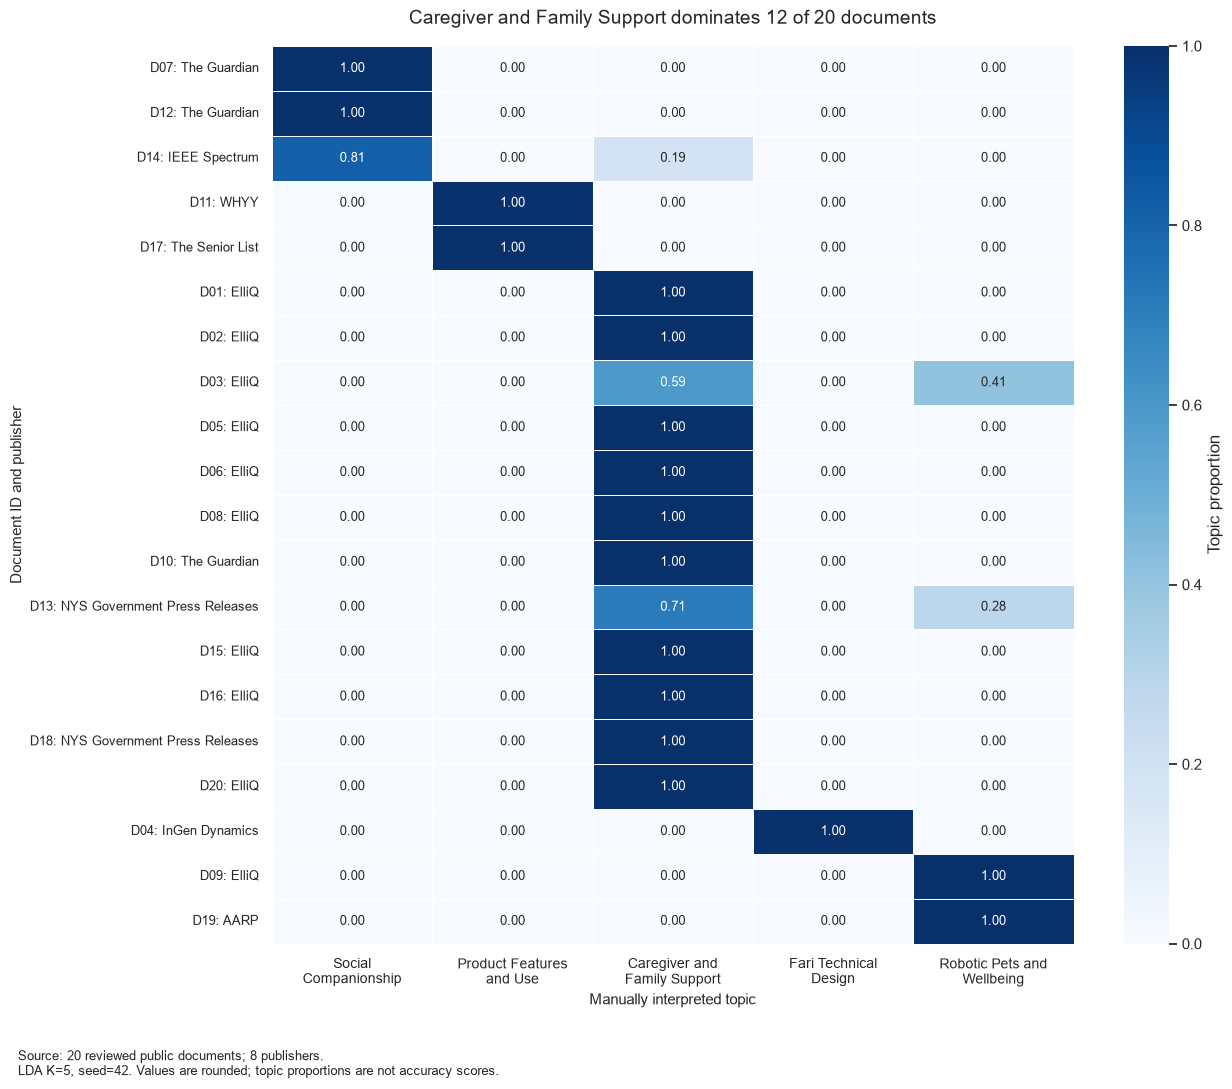

Document-topic heatmap saved: data/lda_selected_v1/figures/W05_LDA_Document_Topic_Heatmap.png


In [34]:
# Visualize all documents' topic proportions.
# Group rows by dominant topic while preserving document identifiers.

from pathlib import Path
import textwrap

import matplotlib.pyplot as plt
import seaborn as sns

# Validate the document-topic matrix.
assert selected_document_topics.shape == (
    len(lda_corpus), selected_k
)

assert np.isfinite(selected_document_topics).all()
assert np.allclose(selected_document_topics.sum(axis=1), 1.0)

# Create short plot IDs and retain their original document mapping.
document_plot_index = lda_corpus[
    ["document_id", "title", "source_name", "source_category"]
].copy()

document_plot_index.insert(
    0,
    "plot_id",
    [f"D{i + 1:02d}" for i in range(len(lda_corpus))],
)

row_labels = [
    f"{row.plot_id}: {row.source_name}"
    for row in document_plot_index.itertuples(index=False)
]

topic_names = [
    topic_labels[f"Topic {i + 1}"]
    for i in range(selected_k)
]

# Group articles by their highest-weight topic.
dominant_topics = selected_document_topics.argmax(axis=1)
plot_order = np.argsort(dominant_topics, kind="stable")

document_topic_heatmap = pd.DataFrame(
    selected_document_topics,
    index=row_labels,
    columns=topic_names,
).iloc[plot_order]

# Build a title that states the main finding.
topic_counts = np.bincount(
    dominant_topics,
    minlength=selected_k,
)

largest_topic = int(topic_counts.argmax())

finding_title = (
    f"{topic_names[largest_topic]} dominates "
    f"{topic_counts[largest_topic]} of {len(lda_corpus)} documents"
)

fig, ax = plt.subplots(figsize=(13, 11))

sns.heatmap(
    document_topic_heatmap,
    cmap="Blues",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 9},
    linewidths=0.4,
    xticklabels=[
        textwrap.fill(name, width=19)
        for name in topic_names
    ],
    yticklabels=True,
    cbar_kws={"label": "Topic proportion"},
    ax=ax,
)

ax.set_title(
    textwrap.fill(finding_title, width=75),
    fontsize=14,
    pad=16,
)

ax.set_xlabel("Manually interpreted topic", fontsize=11)
ax.set_ylabel("Document ID and publisher", fontsize=11)

plt.setp(ax.get_xticklabels(), rotation=0, fontsize=10)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=9)

# Explain the source and the meaning of displayed values.
fig.text(
    0.02,
    0.015,
    f"Source: {len(lda_corpus)} reviewed public documents; "
    f"{lda_corpus['source_name'].nunique()} publishers.\n"
    f"LDA K={selected_k}, seed={RANDOM_STATE}. "
    "Values are rounded; topic proportions are not accuracy scores.",
    fontsize=9,
    ha="left",
)

fig.tight_layout(rect=(0, 0.06, 1, 1))

# Save the figure separately from the TF-IDF baseline.
LDA_DIR = Path("data") / "lda_selected_v1"
LDA_FIGURE_DIR = LDA_DIR / "figures"
LDA_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

heatmap_path = (
    LDA_FIGURE_DIR / "W05_LDA_Document_Topic_Heatmap.png"
)

fig.savefig(
    heatmap_path,
    dpi=200,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.close(fig)

print("Document-topic heatmap saved:", heatmap_path.as_posix())

In [35]:
# Export LDA results and configuration for reproducibility.
import hashlib
import json
from importlib.metadata import version

LDA_DIR.mkdir(parents=True, exist_ok=True)

# Preserve document order and source metadata.
topic_columns = [
    f"Topic {i + 1}" for i in range(selected_k)
]

lda_document_results = lda_corpus[
    ["document_id", "title", "source_name", "source_category"]
].copy().reset_index(drop=True)

lda_document_results[topic_columns] = selected_document_topics

# Dominant topic is the topic with the highest proportion.
dominant_indices = selected_document_topics.argmax(axis=1)

lda_document_results["dominant_topic"] = [
    topic_columns[i] for i in dominant_indices
]

lda_document_results["dominant_topic_label"] = (
    lda_document_results["dominant_topic"].map(topic_labels)
)

lda_document_results["dominant_topic_proportion"] = (
    selected_document_topics.max(axis=1)
)

# Normalize topic-word weights into probabilities.
topic_word_probabilities = (
    selected_model.components_
    / selected_model.components_.sum(axis=1, keepdims=True)
)

lda_topic_words = pd.DataFrame(
    topic_word_probabilities.T,
    index=pd.Index(lda_feature_names, name="term"),
    columns=topic_columns,
).reset_index()

# Save numeric results without rounding.
export_tables = {
    "W05_LDA_Model_Comparison.csv": lda_evaluation,
    "W05_LDA_Selected_Topic_Summary.csv": selected_topic_summary,
    "W05_LDA_Document_Topics.csv": lda_document_results,
    "W05_LDA_Topic_Word_Probabilities.csv": lda_topic_words,
}

for filename, table in export_tables.items():
    table.to_csv(
        LDA_DIR / filename,
        index=False,
        encoding="utf-8-sig",
    )

# Convert the tokenizer callable to a descriptive JSON value.
count_settings_for_json = {
    **LDA_COUNT_SETTINGS,
    "tokenizer": "str.split",
}

input_path = DATA_DIR / "W05_Text_Corpus_Preprocessed.csv"

lda_config = {
    "input_file": input_path.as_posix(),
    "input_sha256": hashlib.sha256(
        input_path.read_bytes()
    ).hexdigest(),
    "document_count": len(lda_corpus),
    "vocabulary_size": len(lda_feature_names),
    "tested_topic_counts": list(TOPIC_COUNTS),
    "selected_topic_count": selected_k,
    "selected_training_perplexity": selected_perplexity,
    "count_vectorizer_settings": count_settings_for_json,
    "selected_model_parameters": selected_model.get_params(),
    "topic_labels": topic_labels,
    "selection_basis": (
        "Training perplexity, topic keywords, and representative "
        "article excerpts; no formal coherence or held-out evaluation."
    ),
    "packages": {
        package: version(package)
        for package in ["numpy", "pandas", "scikit-learn", "scipy"]
    },
    "export_sha256": {
        filename: hashlib.sha256(
            (LDA_DIR / filename).read_bytes()
        ).hexdigest()
        for filename in export_tables
    },
}

(LDA_DIR / "W05_LDA_Config.json").write_text(
    json.dumps(lda_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# Reload document results to verify IDs and proportions.
saved_results = pd.read_csv(
    LDA_DIR / "W05_LDA_Document_Topics.csv",
    keep_default_na=False,
)

assert saved_results["document_id"].tolist() == (
    lda_corpus["document_id"].tolist()
)

assert np.allclose(
    saved_results[topic_columns].to_numpy(dtype=float),
    selected_document_topics,
)

print("LDA exports and reload validation passed.")
print("Output folder:", LDA_DIR.resolve())

LDA exports and reload validation passed.
Output folder: D:\大王只想要工作\intern\Week 5\data\lda_selected_v1


### LDA Topic Selection and Interpretation

Caregiver and Family Support is the dominant topic in 12 of the 20 collected documents (60%). The remaining documents primarily concern social companionship, product features, Fari’s technical design, and robotic pets.

#### Model Selection

LDA models with 3–8 topics were fitted to the document-term count matrix using batch learning, a maximum of 50 iterations, and `random_state=42`. Models were compared using training perplexity.

The six-topic model achieved the lowest training perplexity (1,154.94). The five-topic model was selected for this exploratory analysis after inspecting the top ten terms and one representative article excerpt per topic. Its training perplexity was 1,161.88, approximately 0.6% higher. It separated technical design from robotic-pet discussion while offering more interpretable product-feature terms than the six-topic candidate.

This selection combines model fit with qualitative interpretation. No formal coherence score or held-out perplexity was calculated.

#### Topic Labels and Rationale

| Topic | Label | Rationale |
|---|---|---|
| 1 | Social Companionship | “Robot,” “social,” and “caregiver” suggest companionship and interaction. The representative Guardian article describes an older adult’s everyday relationship with ElliQ. |
| 2 | Product Features and Use | “Feature,” “video,” and “call” suggest product capabilities and communication functions. The representative editorial review discusses ElliQ’s features and user interaction. |
| 3 | Caregiver and Family Support | “Care,” “support,” “family,” and “caregiver” indicate assistance with family caregiving. The representative company article discusses AI’s potential role alongside human care. |
| 4 | Fari Technical Design | “Design,” “model,” “sensor,” and “data” indicate technical architecture. The representative Fari page describes intended monitoring capabilities; this topic reflects company descriptions rather than independently verified performance. |
| 5 | Robotic Pets and Wellbeing | “Dog,” “robotic,” and “pet” indicate robotic-pet discussion. The representative AARP article reports experiences involving comfort, dementia, and loneliness. |

#### Document–Topic Distribution and Limitations

Dominant-topic counts are 3, 2, 12, 1, and 2, respectively. These counts assign each document to its highest-weight topic, although documents can contain multiple topics. For example, D03 has approximately 0.59 weight for Caregiver and Family Support and 0.41 for Robotic Pets and Wellbeing.

The heatmap displays rounded topic proportions. Values near 1.00 indicate concentrated model assignments, not classification accuracy or certainty that a human label is correct.

The corpus is small and includes 55% company content. Topic 4 is dominated by a single document, and labels remain tentative because interpretation used keyword lists and article excerpts. The results describe this collected corpus and should not be generalized to customer preferences, public opinion, or validated product outcomes.